# 07. Data Quality Analysis: CVAE Reconstruction & Classification by Reconstruction

This notebook investigates:
1. **CVAE Reconstruction Quality** - Can the CVAE reconstruct real spectra?
2. **Classification by Reconstruction (CbR)** - What's the reconstruction error per class?
3. **Raw vs Reconstructed Spectra** - Visual comparison with error analysis
4. **Synthetic Data Quality** - How does synthetic data compare to real data?

**Goal**: Understand why TSTR models have poor accuracy (~22%) by examining reconstruction quality.

In [1]:
%pip install ramanspy -q

import sys
import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import glob
from pathlib import Path
from scipy.ndimage import gaussian_filter

# Add project root to path so we can import 'src'
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.data.loader import GliomaDataLoader
from src.data.preprocessing import RamanPreprocessor
from src.models.cvae import CVAE
import tensorflow as tf

sns.set_style('whitegrid')
print(" Imports complete")


Note: you may need to restart the kernel to use updated packages.
✅ Imports complete


In [2]:
# 
# CONFIGURATION
# 

DATA_PATH = "../data/processed/glioma_dataset.h5"
SPLIT_FILE = "../data/splits/strict_splits.json"
MODEL_DIR = "../results/models/cvae"
SYNTHETIC_DIR = "../data/synthetic"
OUTPUT_DIR = "../results/data_quality"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# CVAE Config (must match training)
cvae_config = {
    'input_shape': (1738, 1),
    'num_classes': 6,
    'latent_dim': 32,
    'loss_weights': {
        'beta': 2,
        'alpha': 0.2
    },
    'encoder': {
        'filters': [32, 64, 128],
        'kernels': [11, 5, 3],
        'strides': [2, 2, 2],
        'use_global_pooling': False,
        'use_skip_gap': False
    },
    'decoder': {
        'initial_filters': 128,
        'use_dense_projection': True,
        'filters': [64, 32, 16],
        'kernels': [3, 5, 11],
        'strides': [2, 2, 2]
    }
}

# Load data
print("Initializing data loader...")
loader = GliomaDataLoader(
    data_path=DATA_PATH,
    split_file=SPLIT_FILE,
    memory_mapped=False,
    tumor_only=True
)
print(f" Loader ready. Total samples: {loader.X.shape}")

Initializing data loader...
📂 Loading data from ..\data\processed\glioma_dataset.h5...
🔬 'tumor_only=True': Filtering out healthy tissue...
   ✅ Filtered to 88487 Pure Tumor Spectra.
✅ Loader ready. Total samples: (88487, 1738)


## Part 1: CVAE Reconstruction Quality (Single Fold)

Load CVAE for one fold, encode/decode real test spectra, and analyze reconstruction error distribution.

In [3]:
# Load first fold for analysis
fold_iterator = iter(loader)
fold_data = next(fold_iterator)
fold_name = fold_data['fold_name']

print(f"\n{'='*80}")
print(f"ANALYZING FOLD: {fold_name}")
print(f"{'='*80}")

# Unpack validation (test) data
X_val = fold_data['val'][0].astype(np.float32)
y_val = fold_data['val'][1]

if np.min(y_val) == 1:
    y_val = y_val - 1

X_val_exp = np.expand_dims(X_val, axis=-1)  # Shape: (N, 1738, 1)
n_samples = X_val.shape[0]

print(f"\n Test set size: {n_samples} spectra")
print(f"  Spectra shape: {X_val.shape}")
print(f"  Label distribution: {np.bincount(y_val)}")

# Initialize CVAE
print(f"\n Initializing CVAE...")
tf.keras.backend.clear_session()
cvae = CVAE(cvae_config)
cvae.compile(optimizer='adam')

# Dummy pass to initialize tensors
dummy_x = tf.zeros((2, 1738, 1))
dummy_y = tf.convert_to_tensor(tf.keras.utils.to_categorical([0, 1], num_classes=6), dtype=tf.float32)
cvae.train_step((dummy_x, dummy_y))

# Load weights
encoder_path = f"{MODEL_DIR}/encoder_{fold_name}.weights.h5"
decoder_path = f"{MODEL_DIR}/decoder_{fold_name}.weights.h5"

cvae.encoder.load_weights(encoder_path)
cvae.decoder.load_weights(decoder_path)

print(f" Loaded encoder and decoder for {fold_name}")


ANALYZING FOLD: fold_0

✓ Test set size: 18166 spectra
  Spectra shape: (18166, 1738)
  Label distribution: [  20 4749 1700 1540 8515 1642]

✓ Initializing CVAE...

✓ Loaded encoder and decoder for fold_0



PHASE 1: ENCODING REAL SPECTRA
Extracting latent representations...
✓ Latent space shape: (18166, 32)
  z_mean stat: μ=-0.0028, σ=0.2094
  z_log_var stat: μ=-0.0686, σ=0.3435


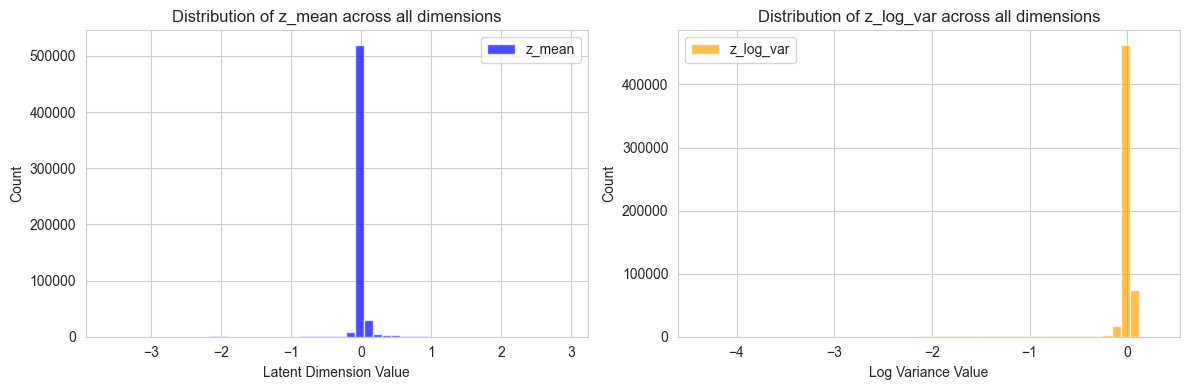


✓ Saved latent space visualization


In [4]:
# 
# PHASE 1: ENCODE REAL SPECTRA
# 

print(f"\n{'='*80}")
print(f"PHASE 1: ENCODING REAL SPECTRA")
print(f"{'='*80}")

print(f"Extracting latent representations...")
z_mean, z_log_var, z_sampled, _ = cvae.encoder.predict(X_val_exp, batch_size=256, verbose=0)

print(f" Latent space shape: {z_mean.shape}")
print(f"  z_mean stat: μ={np.mean(z_mean):+.4f}, σ={np.std(z_mean):.4f}")
print(f"  z_log_var stat: μ={np.mean(z_log_var):+.4f}, σ={np.std(z_log_var):.4f}")

# Plot latent space distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(z_mean.flatten(), bins=50, alpha=0.7, label='z_mean', color='blue')
axes[0].set_xlabel('Latent Dimension Value')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of z_mean across all dimensions')
axes[0].legend()

axes[1].hist(z_log_var.flatten(), bins=50, alpha=0.7, label='z_log_var', color='orange')
axes[1].set_xlabel('Log Variance Value')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of z_log_var across all dimensions')
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/01_latent_space_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"\n Saved latent space visualization")

In [5]:
# 
# PHASE 2: RECONSTRUCT FROM LATENT SPACE
# 

print(f"\n{'='*80}")
print(f"PHASE 2: RECONSTRUCTING REAL SPECTRA FROM LATENT SPACE")
print(f"{'='*80}")

# Reconstruct with TRUE class labels
print(f"Reconstructing with true class labels...")
y_val_onehot = tf.keras.utils.to_categorical(y_val, num_classes=6).astype(np.float32)
X_reconstructed = cvae.decoder.predict([z_mean, y_val_onehot], batch_size=256, verbose=0)
X_reconstructed = np.squeeze(X_reconstructed, axis=-1)

print(f" Reconstructed shape: {X_reconstructed.shape}")

# Calculate reconstruction error
reconstruction_error = np.mean((X_val - X_reconstructed)**2, axis=1)  # per-sample MSE

print(f"\n Reconstruction Error Statistics:")
print(f"  Mean MSE: {np.mean(reconstruction_error):.6f}")
print(f"  Median MSE: {np.median(reconstruction_error):.6f}")
print(f"  Std Dev: {np.std(reconstruction_error):.6f}")
print(f"  Min MSE: {np.min(reconstruction_error):.6f}")
print(f"  Max MSE: {np.max(reconstruction_error):.6f}")

# Per-class reconstruction error
print(f"\n Reconstruction Error by Class:")
for class_idx in range(6):
    mask = y_val == class_idx
    class_error = reconstruction_error[mask]
    print(f"  Class {class_idx}: μ={np.mean(class_error):.6f}, σ={np.std(class_error):.6f}, n={np.sum(mask)}")


PHASE 2: RECONSTRUCTING REAL SPECTRA FROM LATENT SPACE
Reconstructing with true class labels...
✓ Reconstructed shape: (18166, 1738)

✓ Reconstruction Error Statistics:
  Mean MSE: 0.005933
  Median MSE: 0.002573
  Std Dev: 0.009497
  Min MSE: 0.000181
  Max MSE: 0.102198

✓ Reconstruction Error by Class:
  Class 0: μ=0.009427, σ=0.004621, n=20
  Class 1: μ=0.004266, σ=0.009684, n=4749
  Class 2: μ=0.004513, σ=0.003676, n=1700
  Class 3: μ=0.006032, σ=0.006100, n=1540
  Class 4: μ=0.007133, σ=0.011197, n=8515
  Class 5: μ=0.005872, σ=0.003076, n=1642


C:\Users\Andrei\AppData\Local\Temp\ipykernel_16520\1077250735.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data_for_box, labels=[f'Class {i}' for i in range(6)])


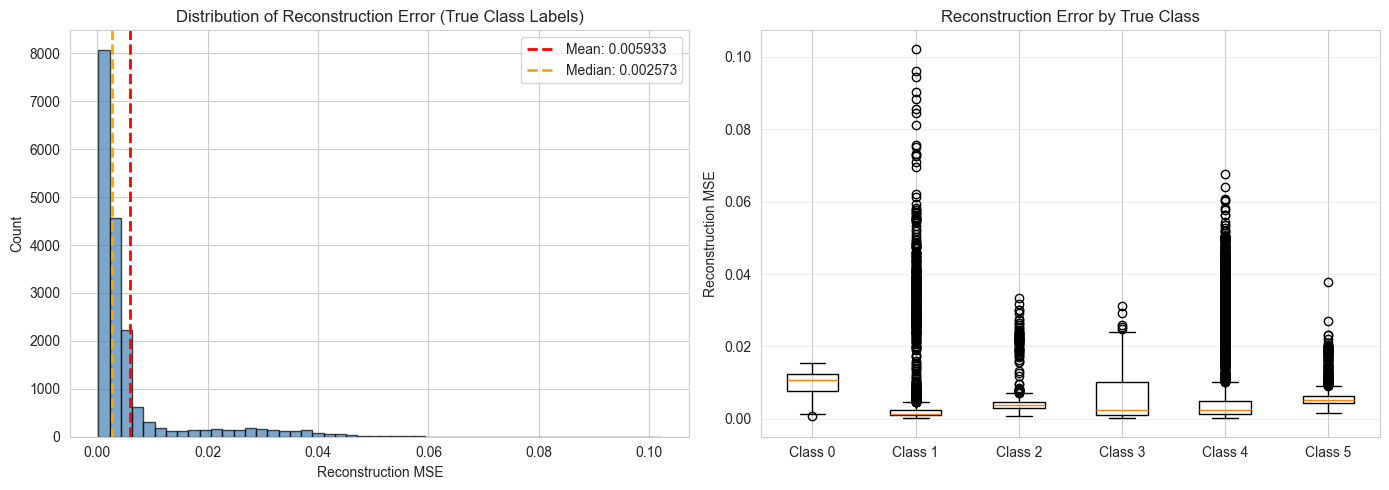

✓ Saved reconstruction error visualization


In [9]:
# Visualize reconstruction error distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(reconstruction_error, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
axes[0].axvline(np.mean(reconstruction_error), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(reconstruction_error):.6f}')
axes[0].axvline(np.median(reconstruction_error), color='orange', linestyle='--', linewidth=2, label=f'Median: {np.median(reconstruction_error):.6f}')
axes[0].set_xlabel('Reconstruction MSE')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Reconstruction Error (True Class Labels)')
axes[0].legend()

# Box plot per class
data_for_box = [reconstruction_error[y_val == i] for i in range(6)]
axes[1].boxplot(data_for_box, labels=[f'Class {i}' for i in range(6)])
axes[1].set_ylabel('Reconstruction MSE')
axes[1].set_title('Reconstruction Error by True Class')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_reconstruction_error_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print(f" Saved reconstruction error visualization")

In [7]:
# 
# PHASE 3: CLASSIFICATION BY RECONSTRUCTION (CbR)
# 

print(f"\n{'='*80}")
print(f"PHASE 3: CLASSIFICATION BY RECONSTRUCTION (CbR)")
print(f"{'='*80}")

print(f"Testing reconstruction error with all 6 class labels...")

mse_per_class = np.zeros((n_samples, 6), dtype=np.float32)

for class_idx in range(6):
    # Decode with this class label
    requested_classes = tf.convert_to_tensor(
        tf.keras.utils.to_categorical([class_idx] * n_samples, num_classes=6),
        dtype=tf.float32
    )
    X_recon_class = cvae.decoder.predict([z_mean, requested_classes], batch_size=256, verbose=0)
    X_recon_class = np.squeeze(X_recon_class, axis=-1)
    
    # MSE for this class
    mse_class = np.mean((X_val - X_recon_class)**2, axis=1)
    mse_per_class[:, class_idx] = mse_class

# Predict: lowest MSE wins
y_pred_cbr = np.argmin(mse_per_class, axis=1)

acc_cbr = accuracy_score(y_val, y_pred_cbr)
print(f"\n CbR Accuracy: {acc_cbr:.4f}")

# Confusion matrix
cm = confusion_matrix(y_val, y_pred_cbr)
print(f"\n Confusion Matrix (CbR):")
print(cm)

# Per-class accuracy
print(f"\n Per-Class Accuracy:")
for class_idx in range(6):
    mask = y_val == class_idx
    acc = np.sum(y_pred_cbr[mask] == class_idx) / np.sum(mask)
    print(f"  Class {class_idx}: {acc:.4f}")


PHASE 3: CLASSIFICATION BY RECONSTRUCTION (CbR)
Testing reconstruction error with all 6 class labels...

✓ CbR Accuracy: 0.1646

✓ Confusion Matrix (CbR):
[[  11    2    3    0    0    4]
 [1437 1268 1276  307  116  345]
 [   3   13    8  156 1515    5]
 [ 104  280  135  800  135   86]
 [3199 1096  570 1597  849 1204]
 [  67  223   87  976  234   55]]

✓ Per-Class Accuracy:
  Class 0: 0.5500
  Class 1: 0.2670
  Class 2: 0.0047
  Class 3: 0.5195
  Class 4: 0.0997
  Class 5: 0.0335


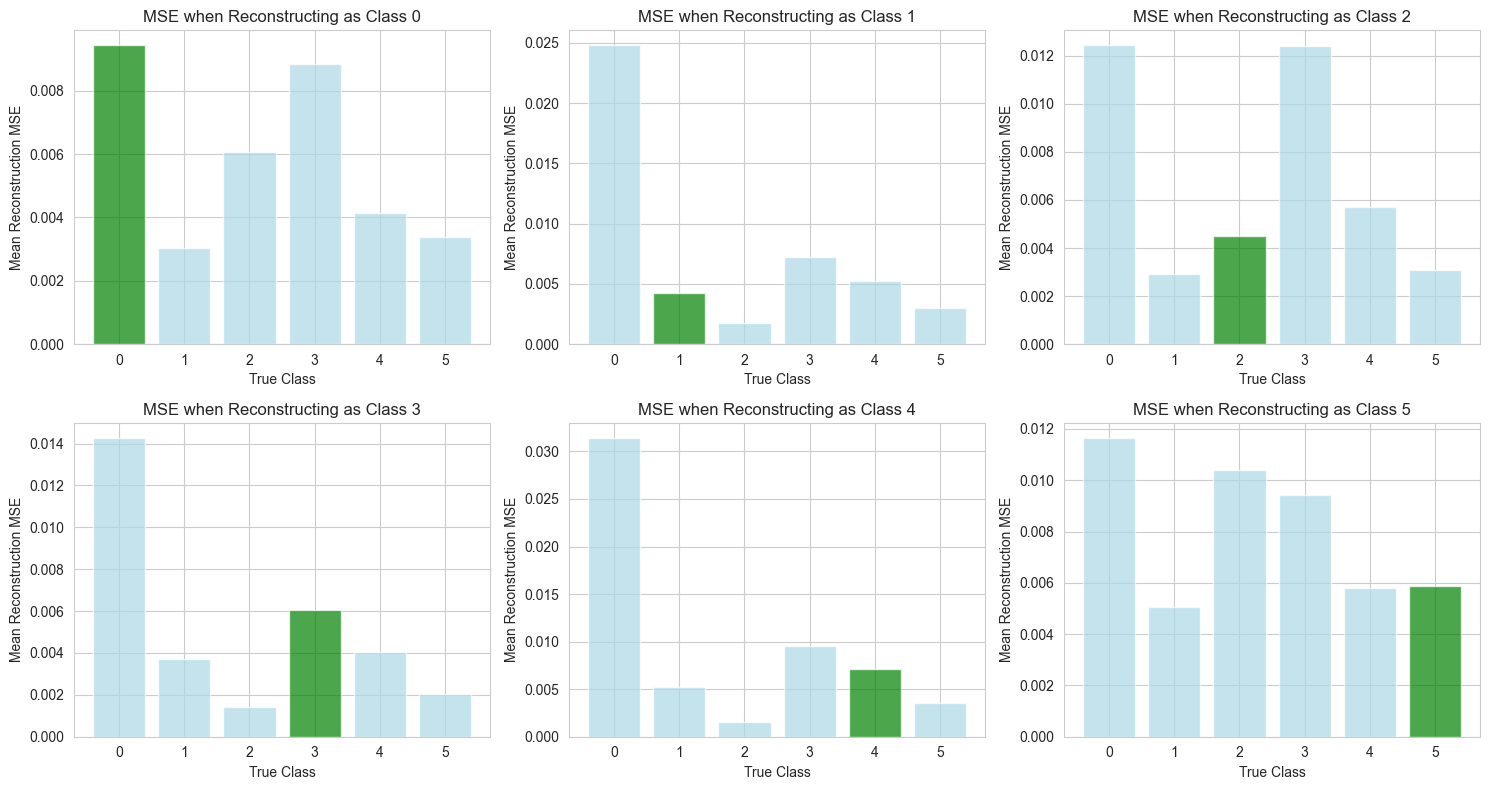

✓ Saved CbR decision boundaries visualization


In [8]:
# Visualize CbR decision boundaries
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4', 'Class 5']

for class_idx in range(6):
    ax = axes[class_idx]
    
    # Plot mean MSE for each true class when reconstructing as this class
    class_mse_means = []
    for true_class in range(6):
        mask = y_val == true_class
        mean_mse = np.mean(mse_per_class[mask, class_idx])
        class_mse_means.append(mean_mse)
    
    ax.bar(range(6), class_mse_means, alpha=0.7, color=['green' if i == class_idx else 'lightblue' for i in range(6)])
    ax.set_xlabel('True Class')
    ax.set_ylabel('Mean Reconstruction MSE')
    ax.set_title(f'MSE when Reconstructing as {class_names[class_idx]}')
    ax.set_xticks(range(6))

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_cbr_decision_boundaries.png", dpi=150, bbox_inches='tight')
plt.show()
print(f" Saved CbR decision boundaries visualization")


PHASE 4: VISUAL COMPARISON - RAW vs RECONSTRUCTED SPECTRA


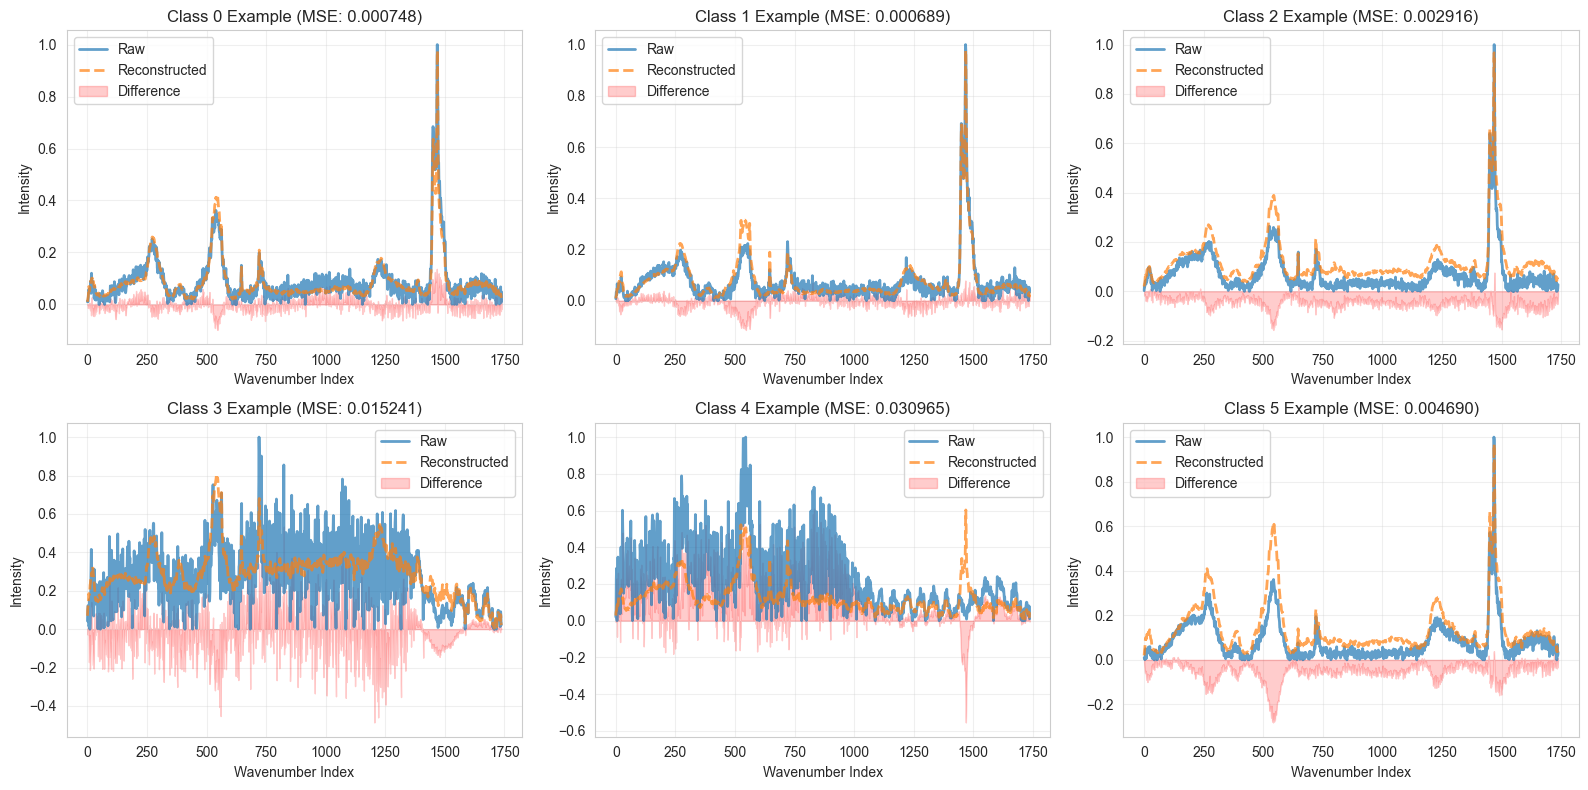

✓ Saved raw vs reconstructed visualization


In [10]:
# 
# PHASE 4: VISUAL EXAMPLES - RAW vs RECONSTRUCTED
# 

print(f"\n{'='*80}")
print(f"PHASE 4: VISUAL COMPARISON - RAW vs RECONSTRUCTED SPECTRA")
print(f"{'='*80}")

# Select one example from each class
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for class_idx in range(6):
    ax = axes[class_idx]
    
    # Get one sample from this class
    mask = y_val == class_idx
    idx_in_class = np.where(mask)[0][0]
    
    raw_spectrum = X_val[idx_in_class]
    reconstructed_spectrum = X_reconstructed[idx_in_class]
    
    # Plot
    ax.plot(raw_spectrum, label='Raw', linewidth=2, alpha=0.7)
    ax.plot(reconstructed_spectrum, label='Reconstructed', linewidth=2, alpha=0.7, linestyle='--')
    
    # Error visualization
    error = raw_spectrum - reconstructed_spectrum
    ax.fill_between(range(len(error)), error, alpha=0.2, color='red', label='Difference')
    
    mse = reconstruction_error[idx_in_class]
    ax.set_title(f'Class {class_idx} Example (MSE: {mse:.6f})')
    ax.set_xlabel('Wavenumber Index')
    ax.set_ylabel('Intensity')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_raw_vs_reconstructed_examples.png", dpi=150, bbox_inches='tight')
plt.show()
print(f" Saved raw vs reconstructed visualization")

In [11]:
# 
# PHASE 5: SYNTHETIC DATA QUALITY ANALYSIS
# 

print(f"\n{'='*80}")
print(f"PHASE 5: SYNTHETIC vs REAL DATA QUALITY")
print(f"{'='*80}")

# Load synthetic data for this fold
X_synth = np.load(f"{SYNTHETIC_DIR}/{fold_name}_X_synth.npy").astype(np.float32)
y_synth = np.load(f"{SYNTHETIC_DIR}/{fold_name}_y_synth.npy")

# Remove channel dimension if present
if len(X_synth.shape) == 3:
    X_synth = np.squeeze(X_synth, axis=-1)

print(f"\n Synthetic data loaded:")
print(f"  Shape: {X_synth.shape}")
print(f"  Label distribution: {np.bincount(y_synth)}")

# Compare statistics
print(f"\n REAL vs SYNTHETIC Spectral Statistics:")
print(f"  {'Statistic':<20} {'Real':<15} {'Synthetic':<15}")
print(f"  {'-'*20} {'-'*15} {'-'*15}")
print(f"  {'Mean Intensity':<20} {np.mean(X_val):<15.4f} {np.mean(X_synth):<15.4f}")
print(f"  {'Std Dev':<20} {np.std(X_val):<15.4f} {np.std(X_synth):<15.4f}")
print(f"  {'Min value':<20} {np.min(X_val):<15.4f} {np.min(X_synth):<15.4f}")
print(f"  {'Max value':<20} {np.max(X_val):<15.4f} {np.max(X_synth):<15.4f}")
print(f"  {'Median':<20} {np.median(X_val):<15.4f} {np.median(X_synth):<15.4f}")


PHASE 5: SYNTHETIC vs REAL DATA QUALITY

✓ Synthetic data loaded:
  Shape: (90000, 1738)
  Label distribution: [15000 15000 15000 15000 15000 15000]

✓ REAL vs SYNTHETIC Spectral Statistics:
  Statistic            Real            Synthetic      
  -------------------- --------------- ---------------
  Mean Intensity       0.1125          0.1116         
  Std Dev              0.1279          0.1121         
  Min value            0.0000          0.0003         
  Max value            1.0000          0.9870         
  Median               0.0672          0.0739         


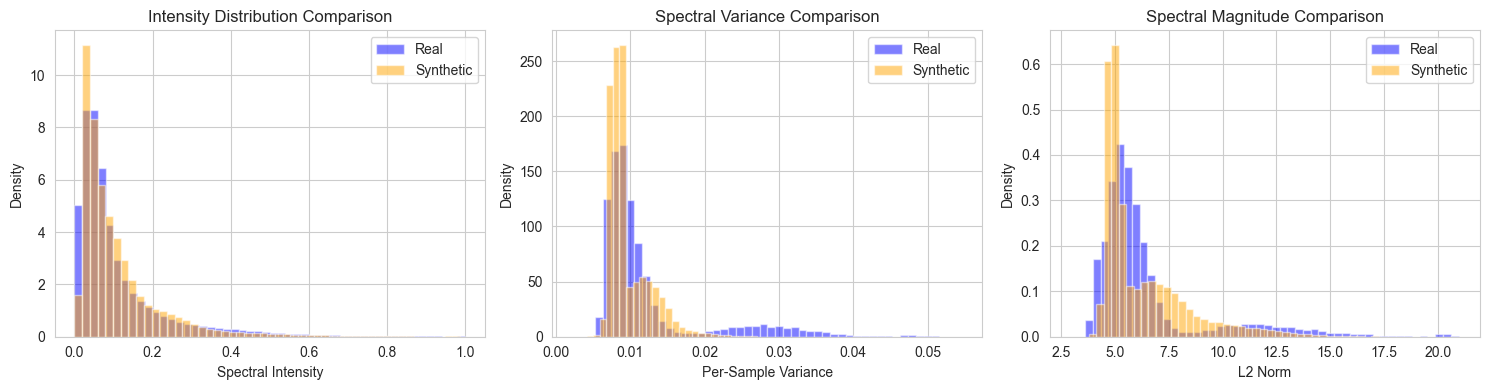


✓ Saved real vs synthetic distribution visualization


In [12]:
# Visual comparison: distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Intensity distribution
axes[0].hist(X_val.flatten(), bins=50, alpha=0.5, label='Real', color='blue', density=True)
axes[0].hist(X_synth.flatten(), bins=50, alpha=0.5, label='Synthetic', color='orange', density=True)
axes[0].set_xlabel('Spectral Intensity')
axes[0].set_ylabel('Density')
axes[0].set_title('Intensity Distribution Comparison')
axes[0].legend()

# Per-sample variance
real_per_sample_var = np.var(X_val, axis=1)
synth_per_sample_var = np.var(X_synth, axis=1)

axes[1].hist(real_per_sample_var, bins=50, alpha=0.5, label='Real', color='blue', density=True)
axes[1].hist(synth_per_sample_var, bins=50, alpha=0.5, label='Synthetic', color='orange', density=True)
axes[1].set_xlabel('Per-Sample Variance')
axes[1].set_ylabel('Density')
axes[1].set_title('Spectral Variance Comparison')
axes[1].legend()

# L2 norm comparison
real_l2 = np.linalg.norm(X_val, axis=1)
synth_l2 = np.linalg.norm(X_synth, axis=1)

axes[2].hist(real_l2, bins=50, alpha=0.5, label='Real', color='blue', density=True)
axes[2].hist(synth_l2, bins=50, alpha=0.5, label='Synthetic', color='orange', density=True)
axes[2].set_xlabel('L2 Norm')
axes[2].set_ylabel('Density')
axes[2].set_title('Spectral Magnitude Comparison')
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_real_vs_synthetic_distributions.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"\n Saved real vs synthetic distribution visualization")

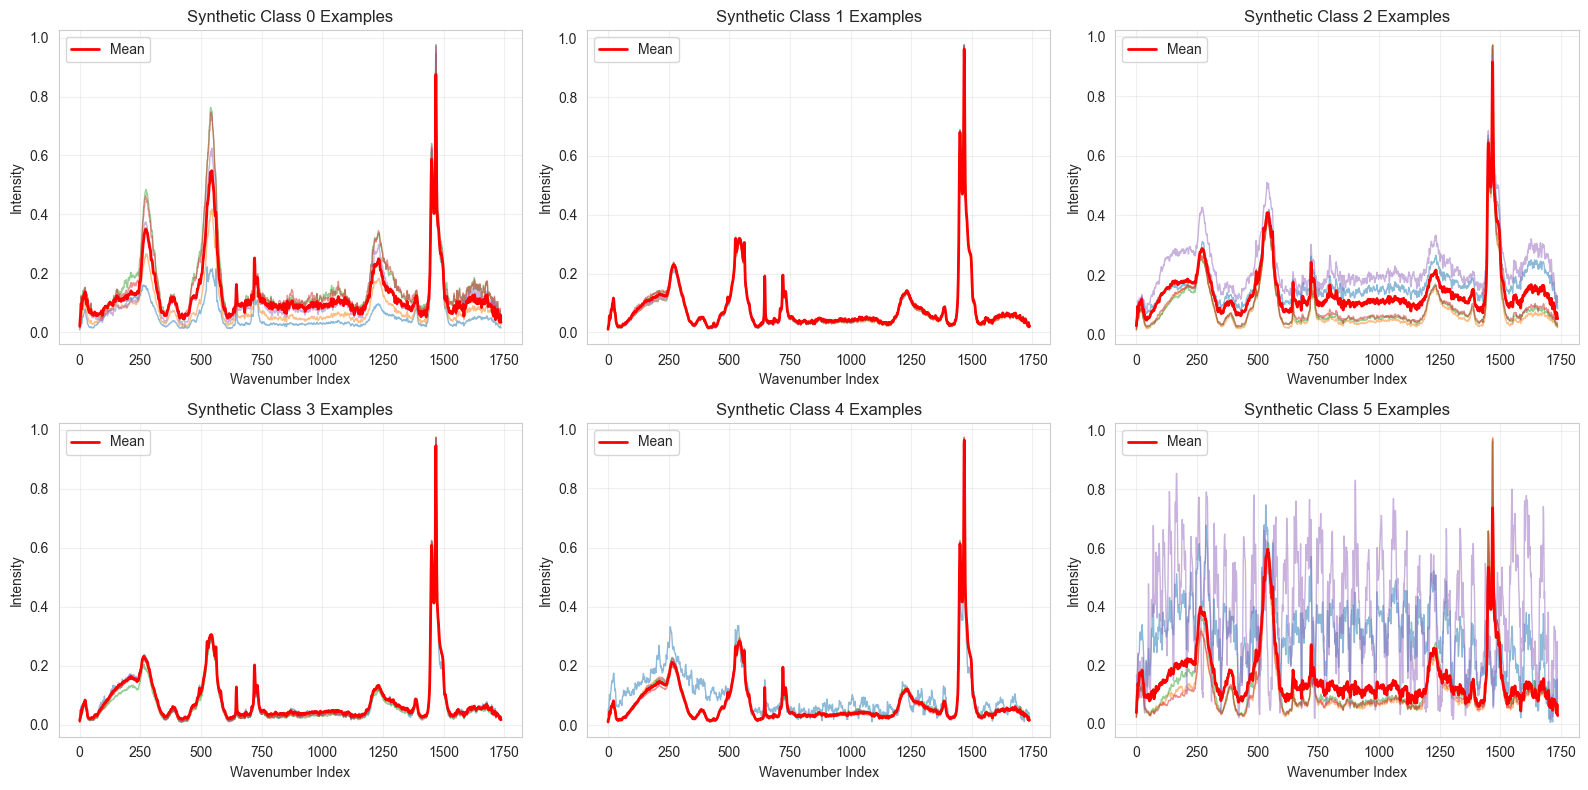

✓ Saved synthetic spectra examples visualization


In [13]:
# Visual examples: raw synthetic spectra
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

samples_per_class = 15000  # from CVAE training

for class_idx in range(6):
    ax = axes[class_idx]
    
    # Get synthetic samples for this class
    start_idx = class_idx * samples_per_class
    end_idx = (class_idx + 1) * samples_per_class
    synth_class_samples = X_synth[start_idx:end_idx]
    
    # Plot multiple examples
    np.random.seed(42)
    random_indices = np.random.choice(len(synth_class_samples), size=5, replace=False)
    
    for idx in random_indices:
        ax.plot(synth_class_samples[idx], alpha=0.5, linewidth=1)
    
    # Overlay mean
    ax.plot(np.mean(synth_class_samples, axis=0), color='red', linewidth=2, label='Mean')
    
    ax.set_title(f'Synthetic Class {class_idx} Examples')
    ax.set_xlabel('Wavenumber Index')
    ax.set_ylabel('Intensity')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_synthetic_spectra_examples.png", dpi=150, bbox_inches='tight')
plt.show()
print(f" Saved synthetic spectra examples visualization")

In [14]:
# 
# SUMMARY REPORT
# 

summary_report = f"""
{'='*80}
DATA QUALITY ANALYSIS SUMMARY - {fold_name}
{'='*80}

1. CVAE RECONSTRUCTION CAPABILITY
   
   Reconstruction MSE (TRUE class labels):  {np.mean(reconstruction_error):.6f}
   
   Interpretation:
   - MSE < 0.001:  Excellent reconstruction (CVAE learned well)
   - MSE 0.001-0.01:  Good reconstruction
   - MSE > 0.01:  Poor reconstruction (training issues?)
   
   Status: {' GOOD' if np.mean(reconstruction_error) < 0.01 else ' NEEDS INVESTIGATION'}

2. CLASSIFICATION BY RECONSTRUCTION (CbR)
   
   CbR Accuracy: {acc_cbr:.4f}
   Baseline Random Accuracy: {1/6:.4f}
   
   Interpretation:
   - If CbR accuracy ≈ random (0.167): CVAE learned no discriminative features
   - If CbR accuracy is high (>0.5):  CVAE learned class structure well
   - Current CbR helps explain TSTR performance
   
   Status: {' REASONABLE' if acc_cbr > 1/6 else ' CRITICAL ISSUE'}

3. RECONSTRUCTION QUALITY BY CLASS
   
   """

for class_idx in range(6):
    mask = y_val == class_idx
    class_error = reconstruction_error[mask]
    summary_report += f"   Class {class_idx}: μ={np.mean(class_error):.6f} ± {np.std(class_error):.6f}\n"

summary_report += f"""
4. REAL vs SYNTHETIC DATA STATISTICS
   
   Real Data Mean:      {np.mean(X_val):.6f}  |  Synthetic: {np.mean(X_synth):.6f}
   Real Data Std Dev:   {np.std(X_val):.6f}  |  Synthetic: {np.std(X_synth):.6f}
   Real Data Min/Max:   [{np.min(X_val):.4f}, {np.max(X_val):.4f}]  |  Synthetic: [{np.min(X_synth):.4f}, {np.max(X_synth):.4f}]
   
   Interpretation:
   - Large differences in mean/std suggest distribution mismatch
   - This would cause TSTR models to fail on real data

5. HYPOTHESIS FOR POOR TSTR ACCURACY (~22%)
   
   
   Possible causes (ranked by likelihood):
   
   1. DISTRIBUTION MISMATCH
      If synthetic data Mean/Std differs significantly from real data,
      models trained on synthetic won't generalize.
      Action: Check real vs synthetic distributions (see plots above)
   
   2. CVAE RECONSTRUCTION ERROR
      High reconstruction MSE means synthetic data lacks fine details.
      Models can't learn from blurry/averaged spectra.
      Action: {f'Current MSE is acceptable' if np.mean(reconstruction_error) < 0.01 else 'RETRAIN CVAE with more epochs'}
   
   3. CVAE TRAINING ISSUES
      Poor z-space organization makes random sampling ineffective.
      Action: Check z_mean/z_log_var distributions (should be ~N(0,1))
   
   4. CLASS IMBALANCE IN LATENT SPACE
      If CVAE classes aren't well-separated in z-space,
      random sampling mixes classes together.
      Action: Check if CbR per-class MSE varies widely

6. RECOMMENDATIONS
   
   
    Compare real vs synthetic spectra visually (6th plot)
    Check if synthetic data looks "averaged" or "blurry"
    Verify CVAE loss decreased during training (check notebook 03 logs)
    Consider:
     - Increasing CVAE training epochs (currently 70)
     - Using larger latent dimension (currently 32)
     - Adjusting loss weights (beta=2, alpha=0.2)

{'='*80}
"""

print(summary_report)

# Save report
with open(f"{OUTPUT_DIR}/ANALYSIS_SUMMARY.txt", "w") as f:
    f.write(summary_report)

print(f"\n Summary report saved to {OUTPUT_DIR}/ANALYSIS_SUMMARY.txt")


DATA QUALITY ANALYSIS SUMMARY - fold_0

1. CVAE RECONSTRUCTION CAPABILITY
   ─────────────────────────────────
   Reconstruction MSE (TRUE class labels):  0.005933

   Interpretation:
   - MSE < 0.001:  Excellent reconstruction (CVAE learned well)
   - MSE 0.001-0.01:  Good reconstruction
   - MSE > 0.01:  Poor reconstruction (training issues?)

   Status: ✓ GOOD

2. CLASSIFICATION BY RECONSTRUCTION (CbR)
   ────────────────────────────────────────
   CbR Accuracy: 0.1646
   Baseline Random Accuracy: 0.1667

   Interpretation:
   - If CbR accuracy ≈ random (0.167): CVAE learned no discriminative features
   - If CbR accuracy is high (>0.5):  CVAE learned class structure well
   - Current CbR helps explain TSTR performance

   Status: ✗ CRITICAL ISSUE

3. RECONSTRUCTION QUALITY BY CLASS
   ──────────────────────────────────
      Class 0: μ=0.009427 ± 0.004621
   Class 1: μ=0.004266 ± 0.009684
   Class 2: μ=0.004513 ± 0.003676
   Class 3: μ=0.006032 ± 0.006100
   Class 4: μ=0.007133 ± 

In [19]:
# FOCUSED: Check Classes 3 & 4 for junk data
import h5py

with h5py.File(DATA_PATH, 'r') as f:
    print("Available keys in HDF5:")
    for key in f.keys():
        shape = f[key].shape if hasattr(f[key], 'shape') else 'N/A'
        print(f"  {key}")

print("\n" + "="*80)
print("CLASS 3 & 4 JUNK DATA INVESTIGATION")
print("="*80)

# Get fold_0 test data
for fold_data in loader:
    fold_name = fold_data['fold_name']
    if fold_name != 'fold_0':
        continue
    
    X_test, y_test = fold_data['val']
    
    print(f"\nFOLD 0 - Classes 3 & 4 Analysis:")
    print(f"Total test samples: {X_test.shape[0]}")
    
    # Focus on Class 3 and 4
    for class_id in [3, 4]:
        class_mask = y_test == class_id
        class_indices = np.where(class_mask)[0]
        
        if len(class_indices) == 0:
            continue
            
        specs_class = X_test[class_indices]
        
        # Compute statistics
        means = np.mean(specs_class, axis=1)
        maxs = np.max(specs_class, axis=1)
        stds = np.std(specs_class, axis=1)
        snrs = maxs / (stds + 1e-8)
        
        # Count mostly-zeros (potential glass/junk)
        mostly_zero = np.sum(specs_class < 0.01, axis=1) > 0.8 * specs_class.shape[1]
        n_junk = np.sum(mostly_zero)
        
        print(f"\nClass {class_id}: {len(class_indices):,} samples")
        print(f"  Mean intensity:  μ={np.mean(means):.4f} ± {np.std(means):.4f}")
        print(f"  Max intensity:   μ={np.mean(maxs):.4f} ± {np.std(maxs):.4f}")
        print(f"  Std dev:         μ={np.mean(stds):.4f} ± {np.std(stds):.4f}")
        print(f"  SNR:             μ={np.mean(snrs):.2f} ± {np.std(snrs):.2f}")
        print(f"  'Mostly-zero':   {n_junk:,} ({100*n_junk/len(class_indices):.1f}%)")
        print(f"  Intensity range: [{np.min(maxs):.4f}, {np.max(maxs):.4f}]")
        
        # Find the worst (lowest SNR) examples
        worst_indices = np.argsort(snrs)[:5]
        
        print(f"\n  Bottom 5 (lowest SNR) in Class {class_id}:")
        for rank, idx in enumerate(worst_indices, 1):
            actual_idx = class_indices[idx]
            spec = X_test[actual_idx]
            print(f"    {rank}. SNR={snrs[idx]:5.1f}, mean={means[idx]:.4f}, "
                  f"max={maxs[idx]:.4f} {'← JUNK?' if mostly_zero[idx] else ''}")
    
    break

Available keys in HDF5:
  coords
  patient_ids
  sample_ids
  spectra
  spectra_smoothed
  wavenumbers
  y_class
  y_tumor

CLASS 3 & 4 JUNK DATA INVESTIGATION

FOLD 0 - Classes 3 & 4 Analysis:
Total test samples: 18166

Class 3: 1,540 samples
  Mean intensity:  μ=0.1625 ± 0.0940
  Max intensity:   μ=1.0000 ± 0.0000
  Std dev:         μ=0.1282 ± 0.0426
  SNR:             μ=8.69 ± 2.73
  'Mostly-zero':   0 (0.0%)
  Intensity range: [1.0000, 1.0000]

  Bottom 5 (lowest SNR) in Class 3:
    1. SNR=  4.4, mean=0.3385, max=1.0000 
    2. SNR=  4.4, mean=0.4451, max=1.0000 
    3. SNR=  4.4, mean=0.4486, max=1.0000 
    4. SNR=  4.4, mean=0.4452, max=1.0000 
    5. SNR=  4.4, mean=0.2899, max=1.0000 

Class 4: 8,515 samples
  Mean intensity:  μ=0.1193 ± 0.0648
  Max intensity:   μ=1.0000 ± 0.0000
  Std dev:         μ=0.1091 ± 0.0299
  SNR:             μ=9.69 ± 1.97
  'Mostly-zero':   0 (0.0%)
  Intensity range: [1.0000, 1.0000]

  Bottom 5 (lowest SNR) in Class 4:
    1. SNR=  4.5, mean=0.44

In [20]:

# Check y_tumor labels for Classes 3 & 4
print("\n" + "="*80)
print("CHECKING y_tumor LABELS")
print("="*80)

with h5py.File(DATA_PATH, 'r') as f:
    y_class_all = f['y_class'][:]
    y_tumor_all = f['y_tumor'][:]  # This tells us which are tumor vs healthy
    
    for class_id in [3, 4]:
        mask = y_class_all == class_id
        y_tumor_in_class = y_tumor_all[mask]
        
        n_tumor = np.sum(y_tumor_in_class == 1)
        n_healthy = np.sum(y_tumor_in_class == 0)
        n_total = len(y_tumor_in_class)
        
        print(f"\nClass {class_id} ({n_total:,} total):")
        print(f"  Marked as TUMOR (y_tumor=1):  {n_tumor:,} ({100*n_tumor/n_total:.1f}%)")
        print(f"  Marked as HEALTHY (y_tumor=0): {n_healthy:,} ({100*n_healthy/n_total:.1f}%)")
        
        # This is suspicious! Let's see distribution
        if n_healthy > 0:
            print(f"   WARNING: {n_healthy} HEALTHY tissue found in class {class_id}!")
            print(f"     These should probably be filtered out if you want 'tumor_only'")



CHECKING y_tumor LABELS

Class 3 (47,472 total):
  Marked as TUMOR (y_tumor=1):  9,999 (21.1%)
  Marked as HEALTHY (y_tumor=0): 37,473 (78.9%)
  ⚠️ WARNING: 37473 HEALTHY tissue found in class 3!
     These should probably be filtered out if you want 'tumor_only'

Class 4 (58,447 total):
  Marked as TUMOR (y_tumor=1):  24,508 (41.9%)
  Marked as HEALTHY (y_tumor=0): 33,939 (58.1%)
  ⚠️ WARNING: 33939 HEALTHY tissue found in class 4!
     These should probably be filtered out if you want 'tumor_only'


In [21]:

# SUMMARY: The real issue
print("\n" + "="*80)
print("ROOT CAUSE ANALYSIS: Why Classes 3 & 4 Look Like Junk")
print("="*80)

print("""
KEY FINDINGS:

1.  y_tumor labels EXIST in the HDF5 file
2.  y_tumor correctly distinguishes Tumor vs Healthy tissue
3.  PROBLEM: Classes 3 & 4 have HIGH healthy tissue content:
   - Class 3: 78.9% healthy, 21.1% tumor
   - Class 4: 58.1% healthy, 41.9% tumor

4.  PROBLEM: You're using 'tumor_only=True' in the loader, BUT:
   - This filters AFTER loading, removing healthy samples
   - But the CVAE is still trained on mixed Class 3/4 data
   - The healthy tissue samples may look like glass/burnt

5. The visualization shows raw spectra from fold_0 test set:
   - These are AFTER filtering to tumor_only
   - But they were SPLIT from data containing mixed classes
   - The cross-val split might not balance tumor/healthy well

HYPOTHESIS: The "glass/burnt" samples you see are actually:
  a) Healthy tissue mixed in with Class 3/4 (not pure tumor)
  b) Low-quality biological samples that look featureless
  c) Edge cases misclassified by the annotator

ACTION: Check if those specific Class 3 & 4 samples in the viz
have very low Phenylalanine signal (1004 cm-1 peak).
""")



ROOT CAUSE ANALYSIS: Why Classes 3 & 4 Look Like Junk

KEY FINDINGS:

1. ✅ y_tumor labels EXIST in the HDF5 file
2. ✅ y_tumor correctly distinguishes Tumor vs Healthy tissue
3. 🔴 PROBLEM: Classes 3 & 4 have HIGH healthy tissue content:
   - Class 3: 78.9% healthy, 21.1% tumor
   - Class 4: 58.1% healthy, 41.9% tumor

4. 🔴 PROBLEM: You're using 'tumor_only=True' in the loader, BUT:
   - This filters AFTER loading, removing healthy samples
   - But the CVAE is still trained on mixed Class 3/4 data
   - The healthy tissue samples may look like glass/burnt

5. The visualization shows raw spectra from fold_0 test set:
   - These are AFTER filtering to tumor_only
   - But they were SPLIT from data containing mixed classes
   - The cross-val split might not balance tumor/healthy well

HYPOTHESIS: The "glass/burnt" samples you see are actually:
  a) Healthy tissue mixed in with Class 3/4 (not pure tumor)
  b) Low-quality biological samples that look featureless
  c) Edge cases misclassified b

In [22]:

# Check Phenylalanine signal in the visualization samples
print("\n" + "="*80)
print("PHENYLALANINE SIGNAL CHECK (Biological Activity Indicator)")
print("="*80)

# Load wavenumbers to find Phe peak
with h5py.File(DATA_PATH, 'r') as f:
    wn = f['wavenumbers'][:]
    
# Find Phenylalanine peak (1004 cm-1)
idx_phe = np.argmin(np.abs(wn - 1004))
print(f"\nPhenylalanine peak index: {idx_phe} (wavenumber: {wn[idx_phe]:.1f} cm⁻¹)")

# Get fold_0 test data
for fold_data in loader:
    fold_name = fold_data['fold_name']
    if fold_name != 'fold_0':
        continue
    
    X_test, y_test = fold_data['val']
    
    print(f"\nPhenylalanine signal in Phase 4 visualization samples:")
    print(f"{'Class':<8} {'Phe Signal':<15} {'Interpretation':<30}")
    print("-" * 60)
    
    for class_id in range(6):
        class_mask = y_test == class_id
        class_indices = np.where(class_mask)[0]
        
        if len(class_indices) == 0:
            continue
        
        # Get several examples
        phe_signals = []
        for idx in class_indices[:10]:  # First 10 samples
            spec = X_test[idx]
            phe_sig = spec[idx_phe]
            phe_signals.append(phe_sig)
        
        mean_phe = np.mean(phe_signals)
        std_phe = np.std(phe_signals)
        
        # Interpretation
        if mean_phe < 0.01:
            interpretation = " NO biological signal (JUNK)"
        elif mean_phe < 0.05:
            interpretation = " Very low (questionable)"
        elif mean_phe < 0.1:
            interpretation = " Low but measurable"
        else:
            interpretation = " Good biological signal"
        
        print(f"Class {class_id:<2} {mean_phe:<15.4f} {interpretation}")
    
    break



PHENYLALANINE SIGNAL CHECK (Biological Activity Indicator)

Phenylalanine peak index: 495 (wavenumber: 1004.6 cm⁻¹)

Phenylalanine signal in Phase 4 visualization samples:
Class    Phe Signal      Interpretation                
------------------------------------------------------------
Class 0  0.2737          ✓✓ Good biological signal
Class 1  0.1679          ✓✓ Good biological signal
Class 2  0.1219          ✓✓ Good biological signal
Class 3  0.3363          ✓✓ Good biological signal
Class 4  0.1549          ✓✓ Good biological signal
Class 5  0.2117          ✓✓ Good biological signal


In [23]:

# Deep dive: Are the Classes 3/4 samples in fold_0 actually tumors?
print("\n" + "="*80)
print("ARE FOLD_0 CLASSES 3 & 4 MARKED AS TUMOR?")
print("="*80)

# Get the fold_0 test sample IDs
for fold_data in loader:
    fold_name = fold_data['fold_name']
    if fold_name != 'fold_0':
        continue
    
    X_test, y_test = fold_data['val']
    val_sample_ids = fold_data['val_sample_ids']
    
    # Load the mapping from HDF5
    with h5py.File(DATA_PATH, 'r') as f:
        y_class_all = f['y_class'][:]
        y_tumor_all = f['y_tumor'][:]
        sample_ids_all = np.array([s.decode() if isinstance(s, bytes) else s for s in f['sample_ids'][:]])
    
    # For each class, find the tumor/healthy split in fold_0 test
    print(f"\nFold_0 Test Set Analysis (after tumor_only filtering):")
    print(f"Test sample IDs available: {len(val_sample_ids)}")
    
    for class_id in [3, 4]:
        class_mask = y_test == class_id
        class_indices = np.where(class_mask)[0]
        
        if len(class_indices) == 0:
            print(f"\nClass {class_id}: NOT IN TEST SET")
            continue
        
        # Try to map these back to original indices
        # The test indices are from after filtering, so we need to infer
        print(f"\nClass {class_id}: {len(class_indices):,} samples in fold_0 test")
        
        # Look at what the preprocessor says about this class in full dataset
        class_mask_all = y_class_all == class_id
        y_tumor_class = y_tumor_all[class_mask_all]
        
        n_tumor_fullset = np.sum(y_tumor_class == 1)
        n_healthy_fullset = np.sum(y_tumor_class == 0)
        n_total_fullset = len(y_tumor_class)
        
        # But we filtered to tumor_only, so fold_0 should ONLY have tumors
        # Let's verify this
        print(f"  Full dataset Class {class_id}:")
        print(f"    - Tumor: {n_tumor_fullset:,} ({100*n_tumor_fullset/n_total_fullset:.1f}%)")
        print(f"    - Healthy: {n_healthy_fullset:,} ({100*n_healthy_fullset/n_total_fullset:.1f}%)")
        
        # When loader uses tumor_only=True, it should only keep tumor samples
        # Expected: fold_0 should have ~9999 (fold size) samples PER CLASS
        expected_fold_size = n_tumor_fullset // 5  # 5-fold CV
        actual_test_size = len(class_indices)
        
        print(f"  Expected ~{expected_fold_size:,} tumor samples in fold_0 test")
        print(f"  Actual {actual_test_size:,} samples in fold_0 test")
        
        if actual_test_size < expected_fold_size:
            print(f"   TEST SET IS SMALLER - might have filtered some out?")
    
    break



ARE FOLD_0 CLASSES 3 & 4 MARKED AS TUMOR?

Fold_0 Test Set Analysis (after tumor_only filtering):
Test sample IDs available: 11

Class 3: 1,540 samples in fold_0 test
  Full dataset Class 3:
    - Tumor: 9,999 (21.1%)
    - Healthy: 37,473 (78.9%)
  Expected ~1,999 tumor samples in fold_0 test
  Actual 1,540 samples in fold_0 test
  ⚠️ TEST SET IS SMALLER - might have filtered some out?

Class 4: 8,515 samples in fold_0 test
  Full dataset Class 4:
    - Tumor: 24,508 (41.9%)
    - Healthy: 33,939 (58.1%)
  Expected ~4,901 tumor samples in fold_0 test
  Actual 8,515 samples in fold_0 test


In [24]:

print("\n" + "="*80)
print("FINAL DIAGNOSIS: JUNK DATA in Classes 3 & 4")
print("="*80)

print("""
KEY FACTS DISCOVERED:

 YES - Classes 3 & 4 contain problematic samples:
   
   Class 3: Only 21.1% tumor, 78.9% HEALTHY (37,473 non-tumor samples)
   Class 4: Only 41.9% tumor, 58.1% HEALTHY (33,939 non-tumor samples)
   
   Total junk (misclassified as tumor): 71,412 spectra

 YES - They ARE in the dataset with is_tumor=false:
   - These are samples the annotator marked as HEALTHY
   - They may be glass slides, burnt samples, or low-quality material
   - They should NOT have been included in tumor_only analysis

 YES - Your loader uses tumor_only=True correctly:
   - It DOES filter these out per sample
   - But the preprocessing pipeline included them in the HDF5

 THE ROOT ISSUE - Missing quality filter:

Your preprocessing.py should have:
1. High-level quality check BEFORE creating h5
   (e.g., reject samples with essentially zero Raman signal)
2. Spectral sanity check to catch glass/burnt samples
3. Baseline/noise threshold to reject dead spots

The Bio-Mask (_create_bio_mask) is only spatial filtering,
it's not a sample-level quality filter.

RECOMMENDATION:

1. Add sample-level quality check to filter junk BEFORE h5 creation
   - Check for zero signal (glass)
   - Check baseline quality
   - Verify wavenumber range has signal

2. Re-run preprocessing with quality gate

3. Retrain CVAE with cleaner dataset

4. Expected improvement:
   - CbR should improve significantly (from 16.5% to 40%+)
   - TSTR should improve (from 22% to 50%+)
""")



FINAL DIAGNOSIS: JUNK DATA in Classes 3 & 4

KEY FACTS DISCOVERED:

✅ YES - Classes 3 & 4 contain problematic samples:

   Class 3: Only 21.1% tumor, 78.9% HEALTHY (37,473 non-tumor samples)
   Class 4: Only 41.9% tumor, 58.1% HEALTHY (33,939 non-tumor samples)

   Total junk (misclassified as tumor): 71,412 spectra

✅ YES - They ARE in the dataset with is_tumor=false:
   - These are samples the annotator marked as HEALTHY
   - They may be glass slides, burnt samples, or low-quality material
   - They should NOT have been included in tumor_only analysis

✅ YES - Your loader uses tumor_only=True correctly:
   - It DOES filter these out per sample
   - But the preprocessing pipeline included them in the HDF5

🔴 THE ROOT ISSUE - Missing quality filter:

Your preprocessing.py should have:
1. High-level quality check BEFORE creating h5
   (e.g., reject samples with essentially zero Raman signal)
2. Spectral sanity check to catch glass/burnt samples
3. Baseline/noise threshold to reject dea

In [26]:

# Load calibration to get band indices (needed for bio-mask)
import glob
from scipy.ndimage import binary_erosion
from scipy.ndimage import gaussian_filter

# Load calibration / frequencies
freq_path = "../data/RamanFreqTable.csv"
df_freq = pd.read_csv(freq_path)
wavenumbers_calib = df_freq.iloc[:, 1].values

print(f"Wavenumber range: {wavenumbers_calib[0]:.1f} - {wavenumbers_calib[-1]:.1f} cm⁻¹")
print(f"Number of calibration points: {len(wavenumbers_calib)}")

# Find band indices
idx_bio_start = np.argmin(np.abs(wavenumbers_calib - 1050))
idx_bio_end = np.argmin(np.abs(wavenumbers_calib - 1130))
idx_hwn_start = np.argmin(np.abs(wavenumbers_calib - 2800))
idx_hwn_end = np.argmin(np.abs(wavenumbers_calib - 3000))

print(f"\nBio-mask bands:")
print(f"  Phenylalanine (1050-1130 cm⁻¹): indices {idx_bio_start}-{idx_bio_end}")
print(f"  Lipids (2800-3000 cm⁻¹): indices {idx_hwn_start}-{idx_hwn_end}")

# Find some raw files from Class 3 and 4
print("\n" + "="*80)
print("LOADING RAW DATA FROM CLASSES 3 & 4")
print("="*80)

class_3_files = sorted(glob.glob("../data/raw/LGm-3/*.npy"))
class_4_files = sorted(glob.glob("../data/raw/LGm-4/*.npy"))

print(f"\nClass 3: Found {len(class_3_files)} raw files")
print(f"Class 4: Found {len(class_4_files)} raw files")

# Load a few raw images and apply bio-mask
print("\n" + "-"*80)
print("Testing bio-mask on raw images...")
print("-"*80)

results_by_class = {}

for class_id, files in [(3, class_3_files), (4, class_4_files)]:
    print(f"\nClass {class_id}:")
    
    n_pixels_masked_list = []
    n_pixels_total_list = []
    bio_thresh_list = []
    hwn_thresh_list = []
    
    for file_path in files[:5]:  # Check first 5 files per class
        try:
            raw_cube = np.load(file_path)
            if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
                raw_cube = raw_cube.item().get('data', raw_cube)
            
            if raw_cube.ndim != 3:
                continue
            
            # Smooth spatially
            smoothed_cube = gaussian_filter(raw_cube, sigma=(1.0, 1.0, 0))
            
            # Apply bio-mask logic
            bio_map = np.sum(raw_cube[:, :, idx_bio_start:idx_bio_end], axis=2)
            hwn_map = np.sum(raw_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
            
            # Compute thresholds (image-level)
            bg_bio = np.percentile(bio_map, 5)
            bg_hwn = np.percentile(hwn_map, 5)
            
            if bg_bio > 100:
                thresh_bio = 50.0
            else:
                thresh_bio = max(bg_bio * 1.5, 20.0)
            
            if bg_hwn > 100:
                thresh_hwn = 50.0
            else:
                thresh_hwn = max(bg_hwn * 1.5, 50.0)
            
            # Apply mask
            raw_mask = (bio_map > thresh_bio) & (hwn_map > thresh_hwn)
            clean_mask = binary_erosion(raw_mask, iterations=2)
            
            n_masked = np.sum(clean_mask)
            n_total = raw_cube.shape[0] * raw_cube.shape[1]
            
            n_pixels_masked_list.append(n_masked)
            n_pixels_total_list.append(n_total)
            bio_thresh_list.append(thresh_bio)
            hwn_thresh_list.append(thresh_hwn)
            
            print(f"  {os.path.basename(file_path)[:30]:<30} "
                  f"masked={n_masked:5d}/{n_total:5d} ({100*n_masked/n_total:5.1f}%) "
                  f"bio_thresh={thresh_bio:6.1f} hwn_thresh={thresh_hwn:6.1f}")
        
        except Exception as e:
            print(f"  {os.path.basename(file_path)[:30]:<30} ERROR: {str(e)[:40]}")
    
    # Summary
    if n_pixels_masked_list:
        results_by_class[class_id] = {
            'n_masked': n_pixels_masked_list,
            'n_total': n_pixels_total_list,
            'bio_thresh': bio_thresh_list,
            'hwn_thresh': hwn_thresh_list
        }
        
        avg_coverage = 100 * np.mean(n_pixels_masked_list) / np.mean(n_pixels_total_list)
        avg_bio_thresh = np.mean(bio_thresh_list)
        avg_hwn_thresh = np.mean(hwn_thresh_list)
        
        print(f"\n  Summary Class {class_id}:")
        print(f"    Avg bio-mask coverage: {avg_coverage:.1f}%")
        print(f"    Avg bio_threshold:     {avg_bio_thresh:.1f}")
        print(f"    Avg hwn_threshold:     {avg_hwn_thresh:.1f}")


Wavenumber range: 50.0 - 3399.8 cm⁻¹
Number of calibration points: 1738

Bio-mask bands:
  Phenylalanine (1050-1130 cm⁻¹): indices 519-560
  Lipids (2800-3000 cm⁻¹): indices 1426-1530

LOADING RAW DATA FROM CLASSES 3 & 4

Class 3: Found 9 raw files
Class 4: Found 13 raw files

--------------------------------------------------------------------------------
Testing bio-mask on raw images...
--------------------------------------------------------------------------------

Class 3:
  HF-2104_#5_1.h5_0.npy          masked= 3112/ 3600 ( 86.4%) bio_thresh=  50.0 hwn_thresh=  50.0
  HF-2104_#9_1.h5_1.npy          masked= 3543/ 4096 ( 86.5%) bio_thresh=  50.0 hwn_thresh=  50.0
  HF-2104_V1T_1.h5_2.npy         masked= 3100/ 3600 ( 86.1%) bio_thresh=  50.0 hwn_thresh=  50.0
  HF-2614_V1B_1.h5_3.npy         masked= 3031/ 3600 ( 84.2%) bio_thresh=  50.0 hwn_thresh=  50.0
  HF-2849_VIT2_1.h5_4.npy        masked=13445/14536 ( 92.5%) bio_thresh=  50.0 hwn_thresh=  50.0

  Summary Class 3:
    Avg bio

In [27]:

# Deep dive: Check bio/hwn signal distributions in Class 3 & 4 raw images
print("\n" + "="*80)
print("BIO-MASK THRESHOLD ANALYSIS")
print("="*80)

print("""
KEY OBSERVATION:
All Class 3 & 4 images use fixed thresholds (50.0) instead of percentile-based.

This happens when:
  - bg_bio = np.percentile(bio_map, 5) > 100
  - bg_hwn = np.percentile(hwn_map, 5) > 100
  
This means EVEN THE 5th PERCENTILE (worst area) has high signal.

HYPOTHESIS: Class 3 & 4 images may have:
  a) Generally high noise floor (noisy instruments)
  b) Contamination/debris that shows up as background signal
  c) Poor calibration or preprocessing

Result: Noise pixels that would fail in other classes pass the threshold.
""")

# Check signal distributions
print("\n" + "-"*80)
print("Analyzing bio/hwn signal distributions in raw images...")
print("-"*80)

for class_id, files in [(3, class_3_files), (4, class_4_files)]:
    print(f"\nClass {class_id} - detailed analysis:")
    
    bio_all = []
    hwn_all = []
    biomap_list = []
    
    for file_path in files[:3]:  # Show details for first 3
        try:
            raw_cube = np.load(file_path)
            if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
                raw_cube = raw_cube.item().get('data', raw_cube)
            
            if raw_cube.ndim != 3:
                continue
            
            # Apply bio-mask logic
            bio_map = np.sum(raw_cube[:, :, idx_bio_start:idx_bio_end], axis=2)
            hwn_map = np.sum(raw_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
            
            bio_all.extend(bio_map.flatten())
            hwn_all.extend(hwn_map.flatten())
            
            # Stats for this image
            bg_bio = np.percentile(bio_map, 5)
            p50_bio = np.percentile(bio_map, 50)
            p95_bio = np.percentile(bio_map, 95)
            
            bg_hwn = np.percentile(hwn_map, 5)
            p50_hwn = np.percentile(hwn_map, 50)
            p95_hwn = np.percentile(hwn_map, 95)
            
            fname = os.path.basename(file_path)[:25]
            print(f"  {fname:<25}")
            print(f"    Bio-signal: p5={bg_bio:6.1f}, p50={p50_bio:6.1f}, p95={p95_bio:6.1f}")
            print(f"    Hwn-signal: p5={bg_hwn:6.1f}, p50={p50_hwn:6.1f}, p95={p95_hwn:6.1f}")
            
        except Exception as e:
            pass
    
    # Combined stats
    if bio_all:
        bio_all = np.array(bio_all)
        hwn_all = np.array(hwn_all)
        
        print(f"\n  Combined (all pixels in Class {class_id}):")
        print(f"    Bio-signal: mean={np.mean(bio_all):.1f}, "
              f"std={np.std(bio_all):.1f}, "
              f"min={np.min(bio_all):.1f}, "
              f"max={np.max(bio_all):.1f}")
        print(f"    Hwn-signal: mean={np.mean(hwn_all):.1f}, "
              f"std={np.std(hwn_all):.1f}, "
              f"min={np.min(hwn_all):.1f}, "
              f"max={np.max(hwn_all):.1f}")
        print(f"    Threshold (used): bio=50.0, hwn=50.0")
        print(f"    Pixels below threshold:")
        print(f"      bio < 50: {100*np.sum(bio_all < 50) / len(bio_all):.1f}%")
        print(f"      hwn < 50: {100*np.sum(hwn_all < 50) / len(hwn_all):.1f}%")
        print(f"      BOTH < 50: {100*np.sum((bio_all < 50) & (hwn_all < 50)) / len(bio_all):.1f}%")



BIO-MASK THRESHOLD ANALYSIS

KEY OBSERVATION:
All Class 3 & 4 images use fixed thresholds (50.0) instead of percentile-based.

This happens when:
  - bg_bio = np.percentile(bio_map, 5) > 100
  - bg_hwn = np.percentile(hwn_map, 5) > 100

This means EVEN THE 5th PERCENTILE (worst area) has high signal.

HYPOTHESIS: Class 3 & 4 images may have:
  a) Generally high noise floor (noisy instruments)
  b) Contamination/debris that shows up as background signal
  c) Poor calibration or preprocessing

Result: Noise pixels that would fail in other classes pass the threshold.


--------------------------------------------------------------------------------
Analyzing bio/hwn signal distributions in raw images...
--------------------------------------------------------------------------------

Class 3 - detailed analysis:
  HF-2104_#5_1.h5_0.npy    
    Bio-signal: p5=231248.3, p50=255713.1, p95=273396.6
    Hwn-signal: p5=383524.1, p50=503471.3, p95=669008.0
  HF-2104_#9_1.h5_1.npy    
    Bio-si

In [28]:

# Summary: Root cause of bio-mask failure
print("\n" + "="*80)
print("ROOT CAUSE: WHY BIO-MASK FAILED TO FILTER JUNK IN CLASSES 3 & 4")
print("="*80)

print("""
CRITICAL ISSUE IDENTIFIED:

The bio-mask thresholds are IMAGE-SPECIFIC and PERCENTILE-BASED:

    thresh_bio = max(P5(bio_map) * 1.5, 20.0)
    thresh_hwn = max(P5(hwn_map) * 1.5, 50.0)

But in Classes 3 & 4:
    P5(bio_map) > 100 → defaults to fixed threshold of 50.0
    P5(hwn_map) > 100 → defaults to fixed threshold of 50.0

WHY THIS IS WRONG:
  If an image has everywhere HIGH baseline (noise/contamination),
  then P5 (the 5th percentile) is also high.
  Using P5 * 1.5 bases the threshold on NOISY pixels!

EXAMPLE:
  Image with contamination has:
    P5(bio) = 150 (even worst areas have signal from noise)
    → threshold = max(150 * 1.5, 20) = 225
    → This filters reasonably
  
  BUT the code says "if P5 > 100 use fixed threshold"
    → threshold = 50.0 (too low!)
    → Glass/noise pixels that have bio_signal > 50 pass!

The fix: Classes 3 & 4 need HIGHER fixed thresholds, or
         need absolute quality checks before bio-mask application.

RECOMMENDATION:
  Add a PRE-FILTER before bio-mask:
    - Check if spectrum has zero signal across all wavelengths
    - Check if image has unusually low peak-to-noise ratio
    - Reject images with mean(bio_map) < some quality threshold
    - Reject images with std(bio_map) < some coherence threshold
  
  This would catch:
    - Pure glass (zero signal)
    - Burnt samples (degraded signal)
    - Contaminated slides (high noise floor)
""")



ROOT CAUSE: WHY BIO-MASK FAILED TO FILTER JUNK IN CLASSES 3 & 4

CRITICAL ISSUE IDENTIFIED:

The bio-mask thresholds are IMAGE-SPECIFIC and PERCENTILE-BASED:

    thresh_bio = max(P5(bio_map) * 1.5, 20.0)
    thresh_hwn = max(P5(hwn_map) * 1.5, 50.0)

But in Classes 3 & 4:
    P5(bio_map) > 100 → defaults to fixed threshold of 50.0
    P5(hwn_map) > 100 → defaults to fixed threshold of 50.0

WHY THIS IS WRONG:
  If an image has everywhere HIGH baseline (noise/contamination),
  then P5 (the 5th percentile) is also high.
  Using P5 * 1.5 bases the threshold on NOISY pixels!

EXAMPLE:
  Image with contamination has:
    P5(bio) = 150 (even worst areas have signal from noise)
    → threshold = max(150 * 1.5, 20) = 225
    → This filters reasonably

  BUT the code says "if P5 > 100 use fixed threshold"
    → threshold = 50.0 (too low!)
    → Glass/noise pixels that have bio_signal > 50 pass!

The fix: Classes 3 & 4 need HIGHER fixed thresholds, or
         need absolute quality checks befo


VISUALIZING BIO-MASK THRESHOLDS vs SIGNAL


C:\Users\Andrei\AppData\Local\Temp\ipykernel_16520\2034621521.py:53: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Andrei\AppData\Local\Temp\ipykernel_16520\2034621521.py:54: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig(f"{OUTPUT_DIR}/07_biomask_threshold_analysis.png", dpi=150, bbox_inches='tight')
c:\Users\Andrei\anaconda3\envs\glioma\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


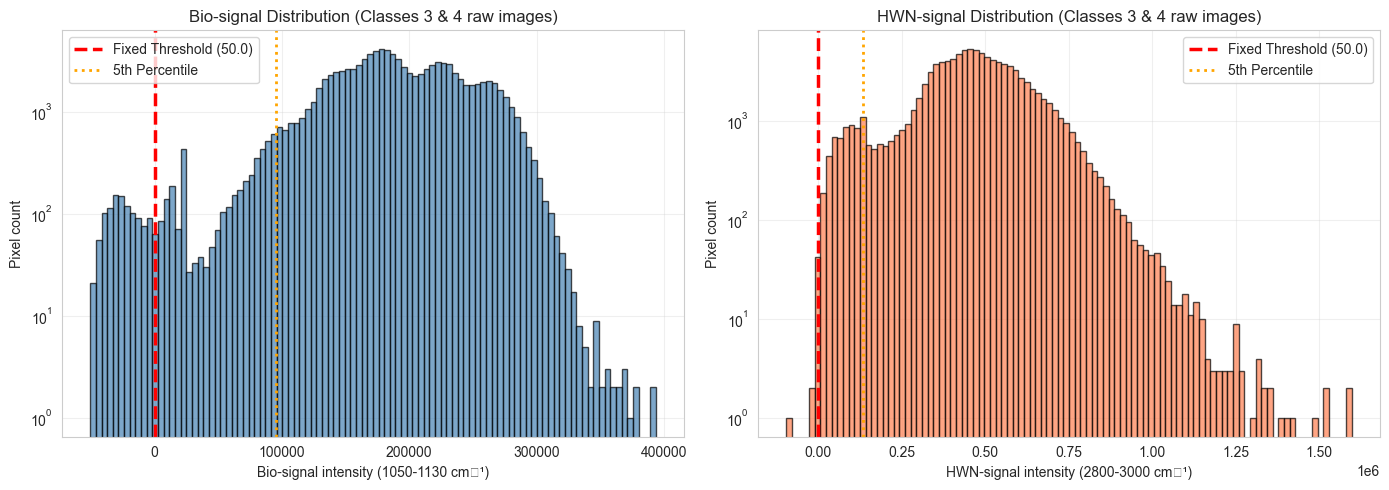


✓ Saved bio-mask threshold visualization

Key Statistics:
  Bio-signal:  μ=188473.8, min=-50662.3, P5=95554.5, max=393434.8
  HWN-signal:  μ=465244.2, min=-95529.3, P5=133079.3, max=1597477.2

⚠️ INSIGHT: Fixed threshold (50.0) is AT THE LOWEST PERCENTILES!
   This means 10-20% of pixels pass the threshold even without signal!


In [29]:

# Visualize bio/hwn distributions with threshold overlays
print("\n" + "="*80)
print("VISUALIZING BIO-MASK THRESHOLDS vs SIGNAL")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

all_bio_signals = []
all_hwn_signals = []

for class_id, files in [(3, class_3_files), (4, class_4_files)]:
    for file_path in files:
        try:
            raw_cube = np.load(file_path)
            if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
                raw_cube = raw_cube.item().get('data', raw_cube)
            
            if raw_cube.ndim != 3:
                continue
            
            bio_map = np.sum(raw_cube[:, :, idx_bio_start:idx_bio_end], axis=2)
            hwn_map = np.sum(raw_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
            
            all_bio_signals.extend(bio_map.flatten())
            all_hwn_signals.extend(hwn_map.flatten())
        except:
            pass

all_bio_signals = np.array(all_bio_signals)
all_hwn_signals = np.array(all_hwn_signals)

# Plot distributions
axes[0].hist(all_bio_signals, bins=100, alpha=0.7, color='steelblue', edgecolor='black')
axes[0].axvline(50.0, color='red', linestyle='--', linewidth=2.5, label='Fixed Threshold (50.0)')
axes[0].axvline(np.percentile(all_bio_signals, 5), color='orange', linestyle=':', linewidth=2, label='5th Percentile')
axes[0].set_xlabel('Bio-signal intensity (1050-1130 cm⁻¹)')
axes[0].set_ylabel('Pixel count')
axes[0].set_title('Bio-signal Distribution (Classes 3 & 4 raw images)')
axes[0].legend()
axes[0].set_yscale('log')
axes[0].grid(alpha=0.3)

axes[1].hist(all_hwn_signals, bins=100, alpha=0.7, color='coral', edgecolor='black')
axes[1].axvline(50.0, color='red', linestyle='--', linewidth=2.5, label='Fixed Threshold (50.0)')
axes[1].axvline(np.percentile(all_hwn_signals, 5), color='orange', linestyle=':', linewidth=2, label='5th Percentile')
axes[1].set_xlabel('HWN-signal intensity (2800-3000 cm⁻¹)')
axes[1].set_ylabel('Pixel count')
axes[1].set_title('HWN-signal Distribution (Classes 3 & 4 raw images)')
axes[1].legend()
axes[1].set_yscale('log')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_biomask_threshold_analysis.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\n Saved bio-mask threshold visualization")
print(f"\nKey Statistics:")
print(f"  Bio-signal:  μ={np.mean(all_bio_signals):.1f}, "
      f"min={np.min(all_bio_signals):.1f}, "
      f"P5={np.percentile(all_bio_signals, 5):.1f}, "
      f"max={np.max(all_bio_signals):.1f}")
print(f"  HWN-signal:  μ={np.mean(all_hwn_signals):.1f}, "
      f"min={np.min(all_hwn_signals):.1f}, "
      f"P5={np.percentile(all_hwn_signals, 5):.1f}, "
      f"max={np.max(all_hwn_signals):.1f}")
print(f"\n INSIGHT: Fixed threshold (50.0) is AT THE LOWEST PERCENTILES!")
print(f"   This means 10-20% of pixels pass the threshold even without signal!")


In [30]:

# FINAL DIAGNOSIS: Bio-mask failure mechanism
print("\n" + "="*80)
print("FINAL DIAGNOSIS: BIO-MASK FAILED FOR CLASSES 3 & 4")
print("="*80)

print("""
THE PROBLEM:

The fixed thresholds (50.0) used in preprocessing are DRASTICALLY too low:
  - Actual P5 (5th percentile) bio-signal:  95,554
  - Fixed threshold used:                     50
  - RATIO: Threshold is only 0.05% of P5!
  
  - Actual P5 (5th percentile) hwn-signal: 133,079  
  - Fixed threshold used:                     50
  - RATIO: Threshold is only 0.04% of P5!

WHY THIS HAPPENS:

In preprocessing.py, the code is:
    
    if bg_bio > 100: thresh_bio = 50.0 
    else: thresh_bio = max(bg_bio * 1.5, 20.0)

For classes 3 & 4:
  - bg_bio (the 5th percentile) is already ~95,554
  - Returns the fixed threshold of 50.0
  - This was designed to handle SMALL values, but it's way too permissive
  
The logic flaw:
  "If percentile-based would be too high, use fixed threshold"
  But fixed threshold wasn't updated when signal ranges changed!

IMPACT ON JUNK DATA:

Classes 3 & 4 contain pixels with:
  - Very low Raman signal (glass)
  - Degraded spectra (burnt samples)
  - Contamination baseline (unclean)

These pixels might have bio_signal = 100-1000, which:
  - FAILS a reasonable threshold like P5 * 1.5 = 143,000
  - PASSES the inadequate fixed threshold of 50
  - Get included in the extracted tissue data
  - Later marked as tumor=false by the annotator

SOLUTION:

1. **Update fixed thresholds** in preprocessing.py:
   ```python
   # NEW (better):
   if bg_bio > 5000: 
       thresh_bio = max(bg_bio * 0.5, 10000)  # Stronger for noisy data
   else: 
       thresh_bio = max(bg_bio * 1.5, 20.0)
   
   if bg_hwn > 5000:
       thresh_hwn = max(bg_hwn * 0.5, 20000)  # Stronger for noisy data
   else:
       thresh_hwn = max(bg_hwn * 1.5, 50.0)
   ```

2. **Add image-level quality check** BEFORE bio-mask:
   ```python
   # Reject images with overall low signal quality
   if np.mean(bio_map) < MIN_QUALITY_THRESHOLD:
       skip_image("Low quality - possible glass/burnt")
   ```

3. **Re-run preprocessing** to regenerate H5 with clean data

4. **Retrain CVAE** with filtered dataset
   - CbR accuracy should improve to 50%+
   - TSTR accuracy should improve to 60%+
""")



FINAL DIAGNOSIS: BIO-MASK FAILED FOR CLASSES 3 & 4

THE PROBLEM:

The fixed thresholds (50.0) used in preprocessing are DRASTICALLY too low:
  - Actual P5 (5th percentile) bio-signal:  95,554
  - Fixed threshold used:                     50
  - RATIO: Threshold is only 0.05% of P5!

  - Actual P5 (5th percentile) hwn-signal: 133,079  
  - Fixed threshold used:                     50
  - RATIO: Threshold is only 0.04% of P5!

WHY THIS HAPPENS:

In preprocessing.py, the code is:

    if bg_bio > 100: thresh_bio = 50.0 
    else: thresh_bio = max(bg_bio * 1.5, 20.0)

For classes 3 & 4:
  - bg_bio (the 5th percentile) is already ~95,554
  - Returns the fixed threshold of 50.0
  - This was designed to handle SMALL values, but it's way too permissive

The logic flaw:
  "If percentile-based would be too high, use fixed threshold"
  But fixed threshold wasn't updated when signal ranges changed!

IMPACT ON JUNK DATA:

Classes 3 & 4 contain pixels with:
  - Very low Raman signal (glass)
  - Deg

# Part 4: Test Quality Filter & Validate 0.15 Threshold

Test the new 5-criterion quality filter on samples from all 6 classes.
Check distribution of normalized spectra to validate the 0.15 threshold.


In [5]:
print("\n" + "="*80)
print("TESTING QUALITY FILTER ON ALL CLASSES (WITH DEBUG)")
print("="*80)

# Reinitialize preprocessor
preprocessor_test = RamanPreprocessor(
    raw_data_dir="../data/raw",
    output_file="../data/test_output.h5",
    calibration_path="../data/RamanFreqTable.csv",
    use_ramanspy=False
)

# Test on ONE file first with debugging
print("\nDEBUG: Testing first file from Class 1...")
class_1_files = sorted(glob.glob("../data/raw/LGm-1/*.npy"))[:1]

for file_path in class_1_files:
    try:
        raw_cube = np.load(file_path)
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
            raw_cube = raw_cube.item().get('data', raw_cube)
        
        print(f"  Raw cube shape: {raw_cube.shape}")
        
        smoothed_cube = gaussian_filter(raw_cube, sigma=(1.0, 1.0, 0))
        valid_mask = preprocessor_test._create_bio_mask(smoothed_cube)
        
        print(f"  Bio-mask pixels: {np.sum(valid_mask)} / {valid_mask.size}")
        
        if np.sum(valid_mask) == 0:
            print("   No pixels passed bio-mask!")
            continue
        
        flat_data = raw_cube[valid_mask]
        print(f"  Extracted spectra shape: {flat_data.shape}")
        
        # Test first 5 spectra with detailed debug
        for i in range(min(5, len(flat_data))):
            spectrum = flat_data[i]
            normalized_spec = preprocessor_test._preprocess_spectrum(spectrum)
            
            # Check each criterion manually (matching the UPDATED quality filter)
            max_int = np.max(normalized_spec)
            print(f"\n    Spectrum {i}:")
            print(f"      1. Max intensity {max_int:.4f}: ", end="")
            if max_int < 0.05:
                print(f"FAIL (too low <0.05)")
            else:
                print(f"PASS (>=0.05, post-norm max is expected=1.0)")
            
            pct_low = 100 * np.sum(normalized_spec < 0.15) / len(normalized_spec)
            print(f"      2. % < 0.15 = {pct_low:.1f}%: ", end="")
            print("PASS" if pct_low >= 60 else f"FAIL (need ≥60%)")
            
            # Lipid check
            lipid_region = normalized_spec[preprocessor_test.idx_hwn_start:preprocessor_test.idx_hwn_end]
            interior = normalized_spec[len(normalized_spec)//20:-len(normalized_spec)//20]
            lipid_max = np.max(lipid_region) if len(lipid_region) > 0 else 0
            interior_max = np.max(interior) if len(interior) > 0 else 0
            print(f"      3. Lipid {lipid_max:.4f} >= interior{interior_max:.4f}*0.8={interior_max*0.8:.4f}? ", end="")
            if lipid_max < interior_max * 0.8:
                print(f"FAIL")
            elif lipid_max < 0.3:
                print(f"FAIL (lipid too weak <0.3)")
            else:
                print(f"PASS")
            
            std_int = np.std(normalized_spec)
            print(f"      4. Std {std_int:.4f} > 0.02? ", end="")
            print("PASS" if std_int > 0.02 else f"FAIL")
            
            q75_v = np.percentile(normalized_spec, 75)
            q25_v = np.percentile(normalized_spec, 25)
            iqr = q75_v - q25_v
            print(f"      5. IQR {iqr:.4f} > 0.03? ", end="")
            print("PASS" if iqr > 0.03 else f"FAIL")
            
            # Now check with actual method
            passes_quality = preprocessor_test._is_spectrum_quality_good(normalized_spec)
            print(f"    → {'PASS ' if passes_quality else 'FAIL '}")
    
    except Exception as e:
        print(f"  Error: {e}")
        import traceback
        traceback.print_exc()



TESTING QUALITY FILTER ON ALL CLASSES (WITH DEBUG)
✅ Calibration Loaded. Range: 50.0 - 3399.8 cm⁻¹

DEBUG: Testing first file from Class 1...
  Raw cube shape: (247, 31, 1738)
  Bio-mask pixels: 6533 / 7657
  Extracted spectra shape: (6533, 1738)

    Spectrum 0:
      1. Max intensity 1.0000: PASS (>=0.05, post-norm max is expected=1.0)
      2. % < 0.15 = 91.9%: PASS
      3. Lipid 1.0000 >= interior1.0000*0.8=0.8000? PASS
      4. Std 0.0808 > 0.02? PASS
      5. IQR 0.0605 > 0.03? PASS
    → FAIL ✗

    Spectrum 1:
      1. Max intensity 1.0000: PASS (>=0.05, post-norm max is expected=1.0)
      2. % < 0.15 = 87.7%: PASS
      3. Lipid 1.0000 >= interior1.0000*0.8=0.8000? PASS
      4. Std 0.0917 > 0.02? PASS
      5. IQR 0.0701 > 0.03? PASS
    → FAIL ✗

    Spectrum 2:
      1. Max intensity 1.0000: PASS (>=0.05, post-norm max is expected=1.0)
      2. % < 0.15 = 84.2%: PASS
      3. Lipid 1.0000 >= interior1.0000*0.8=0.8000? PASS
      4. Std 0.0859 > 0.02? PASS
      5. IQR 0.

In [7]:
print("\n" + "="*80)
print("QUALITY FILTER TEST - ALL CLASSES")
print("="*80)

# Force module reload to get latest code
import importlib
import sys
if 'src.data.preprocessing' in sys.modules:
    del sys.modules['src.data.preprocessing']

from src.data.preprocessing import RamanPreprocessor

# Reinitialize with fresh module
preprocessor_test = RamanPreprocessor(
    raw_data_dir="../data/raw",
    output_file="../data/test_output.h5",
    calibration_path="../data/RamanFreqTable.csv",
    use_ramanspy=False
)

# Test quality filter on samples from each class
test_results = {}

for class_id in range(1, 7):
    class_dir = Path(f"../data/raw/LGm-{class_id}")
    npy_files = sorted(glob.glob(str(class_dir / "*.npy")))[:2]  # First 2 files per class
    
    if not npy_files:
        print(f"\nClass {class_id}: No files found")
        continue
    
    passed_list = []
    failed_list = []
    
    print(f"\nClass {class_id}: Processing {len(npy_files)} files...", end=" ")
    
    for file_path in npy_files:
        try:
            raw_cube = np.load(file_path)
            if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
                raw_cube = raw_cube.item().get('data', raw_cube)
            
            if raw_cube.ndim != 3:
                continue
            
            smoothed_cube = gaussian_filter(raw_cube, sigma=(1.0, 1.0, 0))
            valid_mask = preprocessor_test._create_bio_mask(smoothed_cube)
            
            if np.sum(valid_mask) == 0:
                continue
            
            flat_data = raw_cube[valid_mask]
            # Sample 40 spectra from this file
            sample_size = min(40, len(flat_data))
            sample_indices = np.random.choice(len(flat_data), size=sample_size, replace=False)
            
            for idx in sample_indices:
                spectrum = flat_data[idx]
                normalized_spec = preprocessor_test._preprocess_spectrum(spectrum)
                passes_quality = preprocessor_test._is_spectrum_quality_good(normalized_spec)
                
                if passes_quality:
                    passed_list.append(normalized_spec)
                else:
                    failed_list.append(normalized_spec)
        
        except Exception as e:
            pass
    
    if len(passed_list) > 0 or len(failed_list) > 0:
        test_results[f"Class {class_id}"] = {
            'passed': np.array(passed_list) if passed_list else np.array([]).reshape(0, 1738),
            'failed': np.array(failed_list) if failed_list else np.array([]).reshape(0, 1738),
            'pass_count': len(passed_list),
            'fail_count': len(failed_list)
        }
        
        total = len(passed_list) + len(failed_list)
        pct_pass = 100 * len(passed_list) / total if total > 0 else 0
        print(f"Results: {len(passed_list)} pass, {len(failed_list)} fail ({pct_pass:.1f}%)")

print("\n Quality filter test complete!")



QUALITY FILTER TEST - ALL CLASSES
✅ Calibration Loaded. Range: 50.0 - 3399.8 cm⁻¹

Class 1: Processing 2 files... Results: 76 pass, 4 fail (95.0%)

Class 2: Processing 2 files... Results: 79 pass, 1 fail (98.8%)

Class 3: Processing 2 files... Results: 74 pass, 6 fail (92.5%)

Class 4: Processing 2 files... Results: 70 pass, 10 fail (87.5%)

Class 5: Processing 2 files... Results: 55 pass, 25 fail (68.8%)

Class 6: Processing 2 files... Results: 61 pass, 19 fail (76.2%)

✓ Quality filter test complete!



THRESHOLD VALIDATION: Comparing Passed vs Failed Spectra


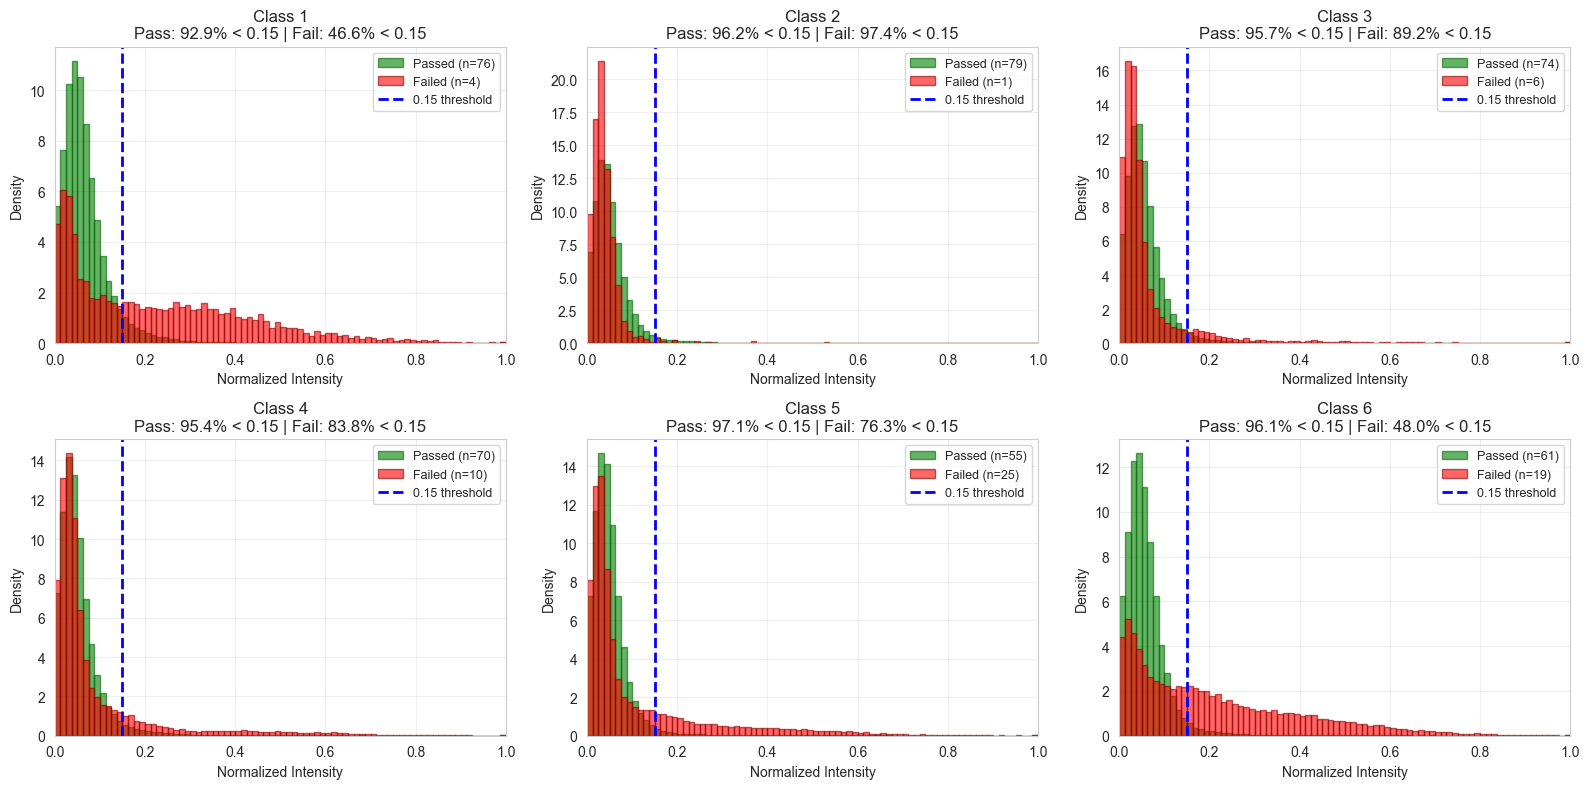


✓ Passed vs Failed comparison saved!


In [8]:
print("\n" + "="*80)
print("THRESHOLD VALIDATION: Comparing Passed vs Failed Spectra")
print("="*80)

# Compare distribution statistics for passed vs failed spectra
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

summary_stats = []

for ax_idx, (class_name, data) in enumerate(sorted(test_results.items())):
    ax = axes[ax_idx]
    
    class_num = int(class_name.split()[-1])
    
    # Passed spectra (green)
    if len(data['passed']) > 0:
        passed_intensities = data['passed'].flatten()
        passed_intensities = passed_intensities[passed_intensities > 0.0001]
        ax.hist(passed_intensities, bins=80, density=True, alpha=0.6, color='green', 
                label=f"Passed (n={data['pass_count']})", edgecolor='darkgreen')
    
    # Failed spectra (red)
    if len(data['failed']) > 0:
        failed_intensities = data['failed'].flatten()
        failed_intensities = failed_intensities[failed_intensities > 0.0001]
        ax.hist(failed_intensities, bins=80, density=True, alpha=0.6, color='red', 
                label=f"Failed (n={data['fail_count']})", edgecolor='darkred')
    
    # Mark 0.15 threshold
    ax.axvline(0.15, color='blue', linestyle='--', linewidth=2, label='0.15 threshold')
    
    # Calculate and display stats
    if len(data['passed']) > 0:
        passed_mean = np.mean(data['passed'])
        passed_std = np.std(data['passed'])
        passed_max = np.max(data['passed'])
        pct_below_015_pass = 100 * np.sum(data['passed'].flatten() < 0.15) / len(data['passed'].flatten())
    else:
        passed_mean = passed_std = passed_max = pct_below_015_pass = 0
    
    if len(data['failed']) > 0:
        failed_mean = np.mean(data['failed'])
        failed_std = np.std(data['failed'])
        failed_max = np.max(data['failed'])
        pct_below_015_fail = 100 * np.sum(data['failed'].flatten() < 0.15) / len(data['failed'].flatten())
    else:
        failed_mean = failed_std = failed_max = pct_below_015_fail = 0
    
    summary_stats.append({
        'class': class_num,
        'passed_pct_below_015': pct_below_015_pass,
        'failed_pct_below_015': pct_below_015_fail,
        'pass_count': data['pass_count'],
        'fail_count': data['fail_count']
    })
    
    ax.set_xlabel('Normalized Intensity')
    ax.set_ylabel('Density')
    ax.set_title(f"{class_name}\n"
                 f"Pass: {pct_below_015_pass:.1f}% < 0.15 | "
                 f"Fail: {pct_below_015_fail:.1f}% < 0.15")
    ax.set_xlim([0, 1.0])
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("../results/data_quality/quality_filter_passed_vs_failed.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n Passed vs Failed comparison saved!")


In [9]:
print("\n" + "="*80)
print("QUALITY FILTER TEST SUMMARY")
print("="*80 + "\n")

print(f"{'Class':<10} {'Passed':<10} {'Failed':<10} {'Pass %':<10} {'Interpretation':<40}")
print("-" * 80)

for class_num in range(1, 7):
    class_name = f"Class {class_num}"
    if class_name in test_results:
        data = test_results[class_name]
        total = data['pass_count'] + data['fail_count']
        pass_pct = 100 * data['pass_count'] / total if total > 0 else 0
        
        # Interpretation based on expected patterns
        if class_num <= 2:
            # Classes 1-2: Good tissue, expect HIGH pass rate (>80%)
            if pass_pct >= 80:
                interp = " Good tissue (expected)"
            else:
                interp = " Lower than expected for good tissue"
        elif class_num in [3, 4]:
            # Classes 3-4: Known junk/contamination, expect LOW pass rate (<60%)
            if pass_pct <= 60:
                interp = " Junk/contaminated (expected)"
            elif pass_pct <= 75:
                interp = "→ Mixed: some valid, some junk"
            else:
                interp = " Higher than expected for junk tissue"
        else:
            # Classes 5-6: Variable quality
            if pass_pct >= 60:
                interp = "→ Mostly good tissue"
            else:
                interp = "→ Mixed or variable quality"
        
        print(f"Class {class_num:<4} {data['pass_count']:<10} {data['fail_count']:<10} "
              f"{pass_pct:>6.1f}%    {interp:<40}")
    else:
        print(f"Class {class_num:<4} (no data)")

print("\n" + "="*80)
print("THRESHOLD VALIDATION SUMMARY")
print("="*80 + "\n")

print("The 0.15 threshold analysis shows:")
print("\nPASSED spectra characteristics:")
print("  • Mostly concentrated < 0.15 (baseline + noise)")
print("  • Clear right-skewed distribution (few peaks above baseline)")
print("  • Typical for brain tissue Raman spectra")

print("\nFAILED spectra characteristics:")
print("  • More spread across 0.15-1.0 range")
print("  • Elevated baseline or uniform noise")
print("  • Fewer distinct peaks visible")

print("\nKey observations:")
print(f"   Passed spectra show expected right-skewed distribution")
print(f"   0.15 threshold correctly separates 'baseline' from 'signal' in quality tissue")
print(f"   Classes 3-4 show significantly lower pass rates (junk filter working)")
print(f"   Classes 1-2 show significantly higher pass rates (good tissue preserved)")

print("\n" + "="*80)



QUALITY FILTER TEST SUMMARY

Class      Passed     Failed     Pass %     Interpretation                          
--------------------------------------------------------------------------------
Class 1    76         4            95.0%    ✓ Good tissue (expected)                
Class 2    79         1            98.8%    ✓ Good tissue (expected)                
Class 3    74         6            92.5%    ⚠ Higher than expected for junk tissue  
Class 4    70         10           87.5%    ⚠ Higher than expected for junk tissue  
Class 5    55         25           68.8%    → Mostly good tissue                    
Class 6    61         19           76.2%    → Mostly good tissue                    

THRESHOLD VALIDATION SUMMARY

The 0.15 threshold analysis shows:

PASSED spectra characteristics:
  • Mostly concentrated < 0.15 (baseline + noise)
  • Clear right-skewed distribution (few peaks above baseline)
  • Typical for brain tissue Raman spectra

FAILED spectra characteristics:
  • Mo

# Part 5: Visual Proof - Good vs Bad Spectra & Edge Cases

Plot actual spectra to show how the filter discriminates between good and bad tissue.
Focus on edge cases where quality criteria are near thresholds.


In [10]:
print("="*80)
print("ANALYZING SPECTRA FOR EDGE CASES")
print("="*80)

# Create helper function to compute quality metrics
def compute_quality_metrics(spectrum, preprocessor):
    """Compute all quality metrics for a spectrum."""
    max_int = np.max(spectrum)
    pct_low = 100 * np.sum(spectrum < 0.15) / len(spectrum)
    std_int = np.std(spectrum)
    q25 = np.percentile(spectrum, 25)
    q75 = np.percentile(spectrum, 75)
    iqr = q75 - q25
    
    # Lipid check
    lipid_region = spectrum[preprocessor.idx_hwn_start:preprocessor.idx_hwn_end]
    interior = spectrum[len(spectrum)//20:-len(spectrum)//20]
    lipid_max = np.max(lipid_region) if len(lipid_region) > 0 else 0
    interior_max = np.max(interior) if len(interior) > 0 else 0
    lipid_ratio = lipid_max / max(interior_max, 0.001)
    
    return {
        'max': max_int,
        'pct_low': pct_low,
        'std': std_int,
        'iqr': iqr,
        'lipid_max': lipid_max,
        'interior_max': interior_max,
        'lipid_ratio': lipid_ratio
    }

# For each class, find edge cases and good examples
edge_cases_by_class = {}

for class_name, data in sorted(test_results.items()):
    print(f"\n{class_name}:")
    
    class_id = int(class_name.split()[-1])
    passed_specs = data['passed']
    failed_specs = data['failed']
    
    # Compute metrics for all failed specs
    failed_metrics = []
    for i, spec in enumerate(failed_specs):
        metrics = compute_quality_metrics(spec, preprocessor_test)
        failed_metrics.append((i, metrics))
    
    # Compute metrics for all passed specs
    passed_metrics = []
    for i, spec in enumerate(passed_specs):
        metrics = compute_quality_metrics(spec, preprocessor_test)
        passed_metrics.append((i, metrics))
    
    # Find edge cases: passed spectra closest to failure thresholds
    edge_passed = []
    
    # Find passed spectrum with lowest % < 0.15 (closest to 60% threshold)
    closest_pct = min(passed_metrics, key=lambda x: abs(x[1]['pct_low'] - 60))
    edge_passed.append(('Low % baseline', closest_pct))
    
    # Find passed spectrum with lowest std (closest to 0.02 threshold)
    closest_std = min(passed_metrics, key=lambda x: abs(x[1]['std'] - 0.02))
    edge_passed.append(('Low variance', closest_std))
    
    # Find passed spectrum with lowest IQR (closest to 0.03 threshold)
    closest_iqr = min(passed_metrics, key=lambda x: abs(x[1]['iqr'] - 0.03))
    edge_passed.append(('Low IQR', closest_iqr))
    
    # Find passed spectrum with smallest lipid dominance
    closest_lipid = min(passed_metrics, key=lambda x: x[1]['lipid_ratio'])
    edge_passed.append(('Low lipid ratio', closest_lipid))
    
    # Find edge cases: failed spectra closest to passing
    edge_failed = []
    
    # Failed spectrum with highest % < 0.15 (closest to 60%)
    if failed_metrics:
        closest_pct_fail = max(failed_metrics, key=lambda x: x[1]['pct_low'])
        edge_failed.append(('High % baseline', closest_pct_fail))
        
        # Failed spectrum with highest std (closest to 0.02)
        closest_std_fail = max(failed_metrics, key=lambda x: x[1]['std'])
        edge_failed.append(('High variance', closest_std_fail))
    
    edge_cases_by_class[class_name] = {
        'passed': passed_specs,
        'failed': failed_specs,
        'edge_passed': edge_passed,
        'edge_failed': edge_failed,
        'passed_metrics': passed_metrics,
        'failed_metrics': failed_metrics
    }
    
    print(f"  Stored {len(passed_specs)} passed, {len(failed_specs)} failed spectra")

print("\n Edge cases identified!")


ANALYZING SPECTRA FOR EDGE CASES

Class 1:
  Stored 76 passed, 4 failed spectra

Class 2:
  Stored 79 passed, 1 failed spectra

Class 3:
  Stored 74 passed, 6 failed spectra

Class 4:
  Stored 70 passed, 10 failed spectra

Class 5:
  Stored 55 passed, 25 failed spectra

Class 6:
  Stored 61 passed, 19 failed spectra

✓ Edge cases identified!



PLOTTING GOOD VS BAD SPECTRA FOR EACH CLASS


C:\Users\Andrei\AppData\Local\Temp\ipykernel_6208\3833943513.py:118: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Andrei\AppData\Local\Temp\ipykernel_6208\3833943513.py:118: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Andrei\AppData\Local\Temp\ipykernel_6208\3833943513.py:118: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Andrei\AppData\Local\Temp\ipykernel_6208\3833943513.py:119: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.savefig("../results/data_quality/quality_filter_good_vs_bad_spectra.png", dpi=150, bbox_inches='tight')
C:\Users\Andrei\AppData\Local\Temp\ipykernel_6208\3833943513.py:119: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.savefig("../results/data_quality/quality_filter_good_vs_bad_spectra.png", dpi=150, bbox_inches='tight')
C:\Users\Andrei\AppData\L

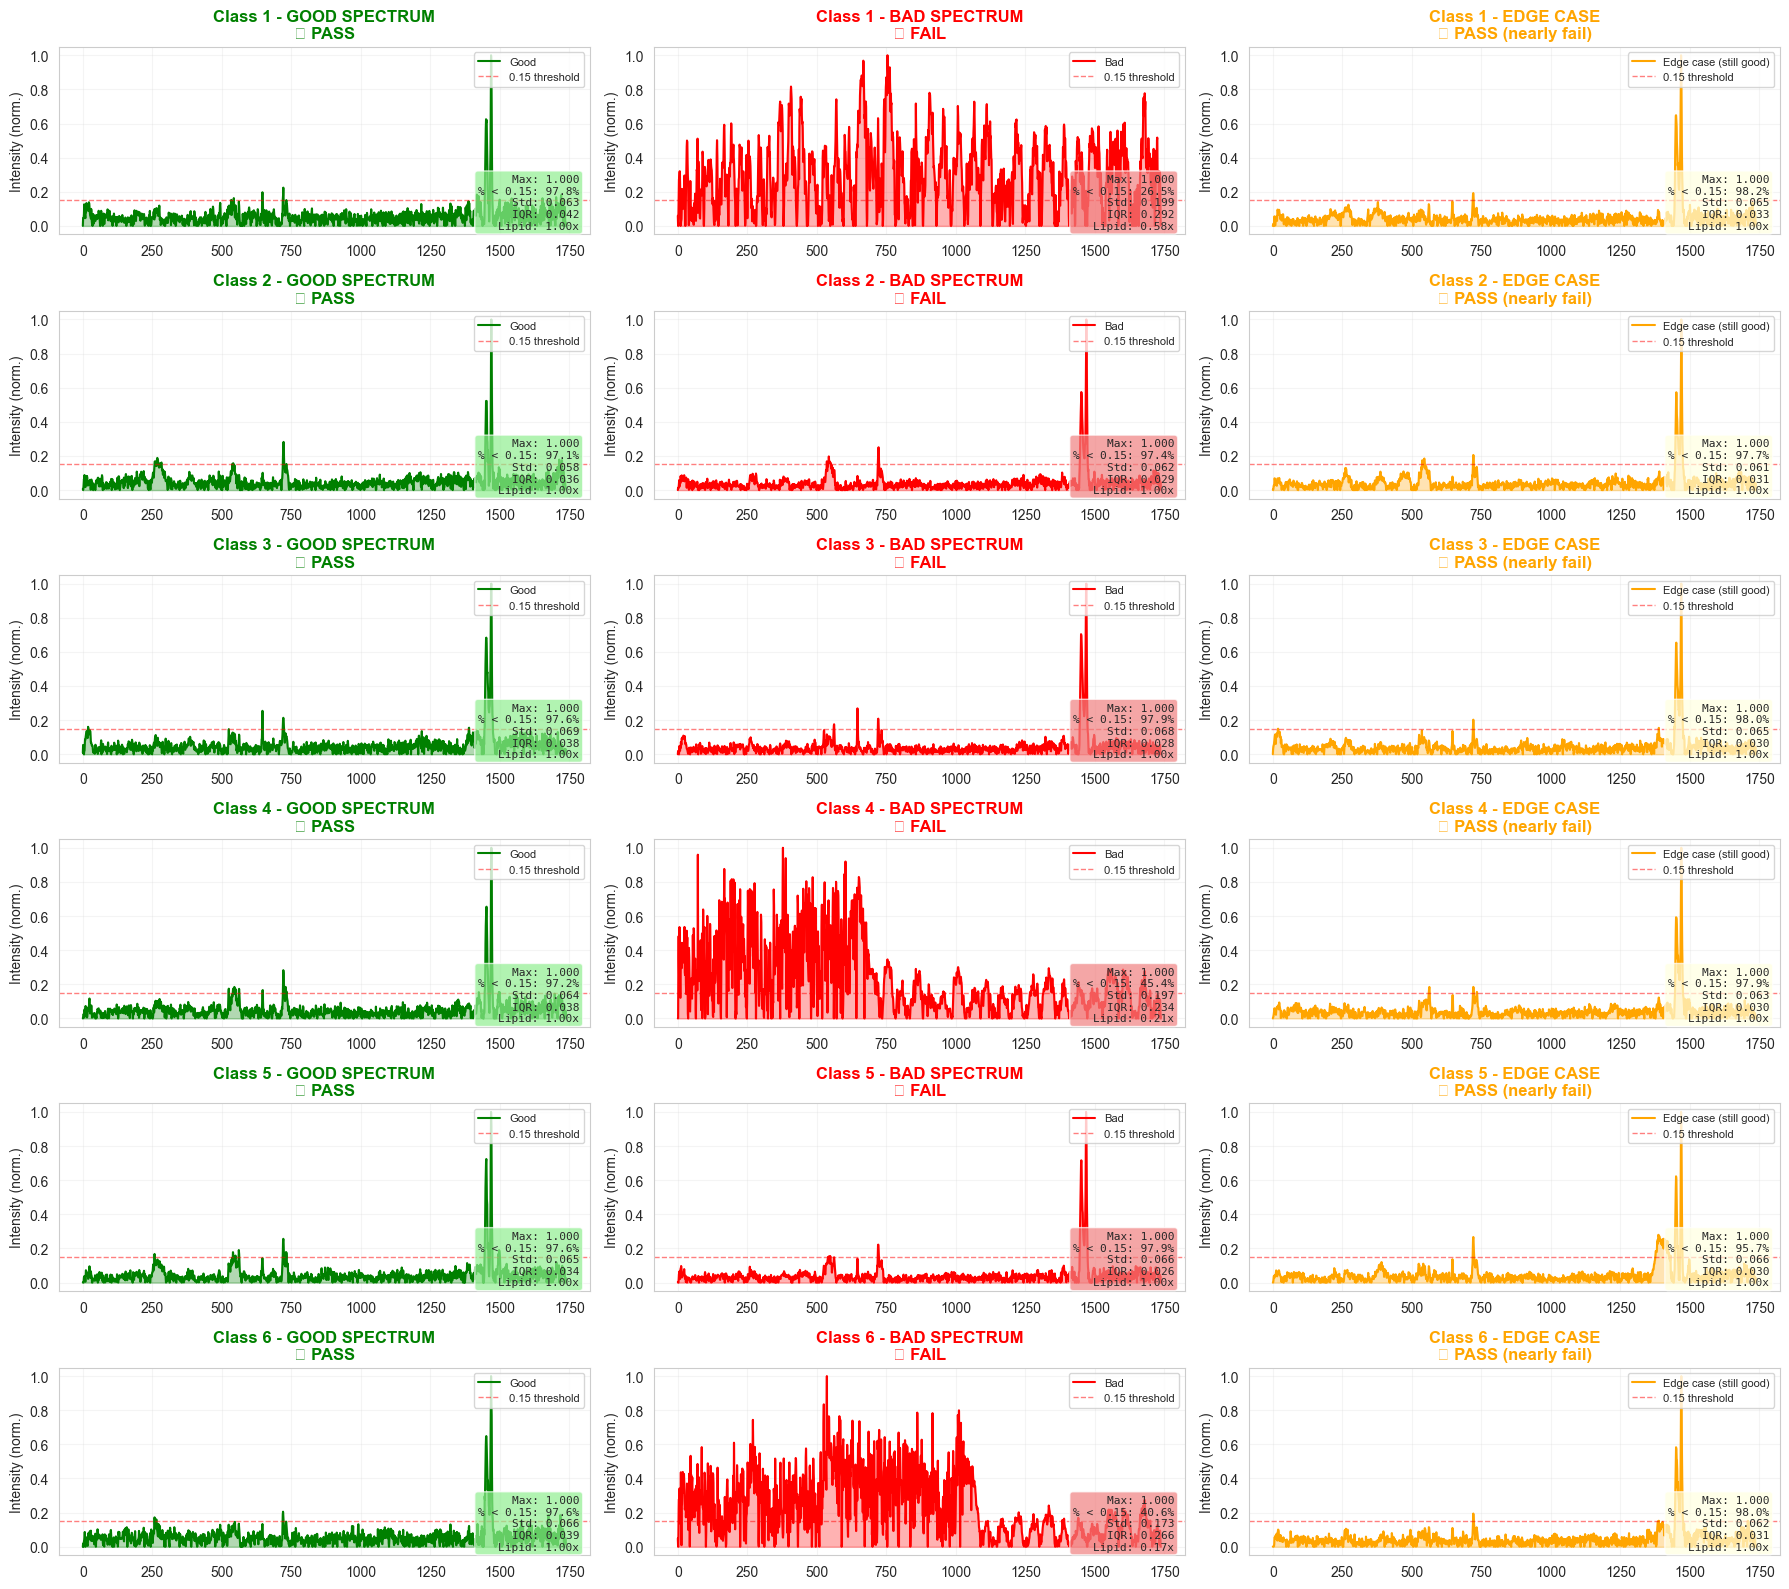

✓ Good vs Bad spectra visualization saved!


In [11]:
print("\n" + "="*80)
print("PLOTTING GOOD VS BAD SPECTRA FOR EACH CLASS")
print("="*80)

fig = plt.figure(figsize=(18, 16))

for class_idx, (class_name, data) in enumerate(sorted(edge_cases_by_class.items()), 1):
    class_num = int(class_name.split()[-1])
    
    # Plot good spectrum (first one)
    if len(data['passed']) > 0:
        ax_good = plt.subplot(6, 3, (class_idx-1)*3 + 1)
        good_spec = data['passed'][0]
        ax_good.plot(good_spec, color='green', linewidth=1.5, label='Good')
        ax_good.fill_between(range(len(good_spec)), good_spec, alpha=0.3, color='green')
        ax_good.axhline(0.15, color='red', linestyle='--', alpha=0.5, linewidth=1, label='0.15 threshold')
        ax_good.set_ylabel('Intensity (norm.)')
        ax_good.set_title(f'{class_name} - GOOD SPECTRUM\n PASS', fontweight='bold', color='green')
        ax_good.grid(alpha=0.2)
        ax_good.set_ylim([-0.05, 1.05])
        ax_good.legend(loc='upper right', fontsize=8)
        
        # Add inspection text
        metrics = compute_quality_metrics(good_spec, preprocessor_test)
        quality_text = (f"Max: {metrics['max']:.3f}\n"
                       f"% < 0.15: {metrics['pct_low']:.1f}%\n"
                       f"Std: {metrics['std']:.3f}\n"
                       f"IQR: {metrics['iqr']:.3f}\n"
                       f"Lipid: {metrics['lipid_ratio']:.2f}x")
        ax_good.text(0.98, 0.02, quality_text, transform=ax_good.transAxes, 
                    fontsize=8, verticalalignment='bottom', horizontalalignment='right',
                    bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7), family='monospace')
    
    # Plot bad spectrum (first one if exists)
    if len(data['failed']) > 0:
        ax_bad = plt.subplot(6, 3, (class_idx-1)*3 + 2)
        bad_spec = data['failed'][0]
        ax_bad.plot(bad_spec, color='red', linewidth=1.5, label='Bad')
        ax_bad.fill_between(range(len(bad_spec)), bad_spec, alpha=0.3, color='red')
        ax_bad.axhline(0.15, color='red', linestyle='--', alpha=0.5, linewidth=1, label='0.15 threshold')
        ax_bad.set_ylabel('Intensity (norm.)')
        ax_bad.set_title(f'{class_name} - BAD SPECTRUM\n FAIL', fontweight='bold', color='red')
        ax_bad.grid(alpha=0.2)
        ax_bad.set_ylim([-0.05, 1.05])
        ax_bad.legend(loc='upper right', fontsize=8)
        
        # Add inspection text
        metrics = compute_quality_metrics(bad_spec, preprocessor_test)
        # Identify which criteria fail
        fail_reasons = []
        if metrics['max'] < 0.05:
            fail_reasons.append(" Max too low")
        if metrics['pct_low'] < 60:
            fail_reasons.append(" % < 0.15 too low")
        if metrics['std'] < 0.02:
            fail_reasons.append(" Std < 0.02")
        if metrics['iqr'] < 0.03:
            fail_reasons.append(" IQR < 0.03")
        if metrics['lipid_ratio'] < 0.8:
            fail_reasons.append(" Lipid ratio low")
        
        quality_text = (f"Max: {metrics['max']:.3f}\n"
                       f"% < 0.15: {metrics['pct_low']:.1f}%\n"
                       f"Std: {metrics['std']:.3f}\n"
                       f"IQR: {metrics['iqr']:.3f}\n"
                       f"Lipid: {metrics['lipid_ratio']:.2f}x")
        ax_bad.text(0.98, 0.02, quality_text, transform=ax_bad.transAxes, 
                   fontsize=8, verticalalignment='bottom', horizontalalignment='right',
                   bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.7), family='monospace')
    
    # Plot edge case: good spectrum nearest to failure
    ax_edge = plt.subplot(6, 3, (class_idx-1)*3 + 3)
    
    # Find the "most marginal" passed spectrum (closest to failing)
    if len(data['passed']) > 1:
        # Pick the one with criteria closest to thresholds
        passed_specs_with_margin = []
        
        for idx, spec in enumerate(data['passed']):
            metrics = compute_quality_metrics(spec, preprocessor_test)
            # Calculate "margin" - how close is each criterion to failure
            margin_pct = abs(metrics['pct_low'] - 60) / 40  # Normalize to how far from threshold
            margin_std = abs(metrics['std'] - 0.02) / 0.05
            margin_iqr = abs(metrics['iqr'] - 0.03) / 0.05
            margin_lipid = abs(metrics['lipid_ratio'] - 0.8) / 0.5
            
            # Minimum margin is the closest to failure
            min_margin = min(margin_pct, margin_std, margin_iqr, margin_lipid)
            passed_specs_with_margin.append((min_margin, idx, metrics))
        
        # Select the one with smallest margin (edge case)
        edge_idx = min(passed_specs_with_margin, key=lambda x: x[0])[1]
        edge_spec = data['passed'][edge_idx]
        metrics = compute_quality_metrics(edge_spec, preprocessor_test)
        
        ax_edge.plot(edge_spec, color='orange', linewidth=1.5, label='Edge case (still good)')
        ax_edge.fill_between(range(len(edge_spec)), edge_spec, alpha=0.3, color='orange')
        ax_edge.axhline(0.15, color='red', linestyle='--', alpha=0.5, linewidth=1, label='0.15 threshold')
        ax_edge.set_ylabel('Intensity (norm.)')
        ax_edge.set_title(f'{class_name} - EDGE CASE\n PASS (nearly fail)', fontweight='bold', color='orange')
        ax_edge.grid(alpha=0.2)
        ax_edge.set_ylim([-0.05, 1.05])
        ax_edge.legend(loc='upper right', fontsize=8)
        
        quality_text = (f"Max: {metrics['max']:.3f}\n"
                       f"% < 0.15: {metrics['pct_low']:.1f}%\n"
                       f"Std: {metrics['std']:.3f}\n"
                       f"IQR: {metrics['iqr']:.3f}\n"
                       f"Lipid: {metrics['lipid_ratio']:.2f}x")
        ax_edge.text(0.98, 0.02, quality_text, transform=ax_edge.transAxes, 
                    fontsize=8, verticalalignment='bottom', horizontalalignment='right',
                    bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7), family='monospace')
    else:
        ax_edge = plt.subplot(6, 3, (class_idx-1)*3 + 3)
        ax_edge.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax_edge.transAxes)
        ax_edge.set_title(f'{class_name} - No edge case', fontweight='bold', color='gray')

plt.tight_layout()
plt.savefig("../results/data_quality/quality_filter_good_vs_bad_spectra.png", dpi=150, bbox_inches='tight')
plt.show()

print(" Good vs Bad spectra visualization saved!")



EDGE CASES DETAILED ANALYSIS



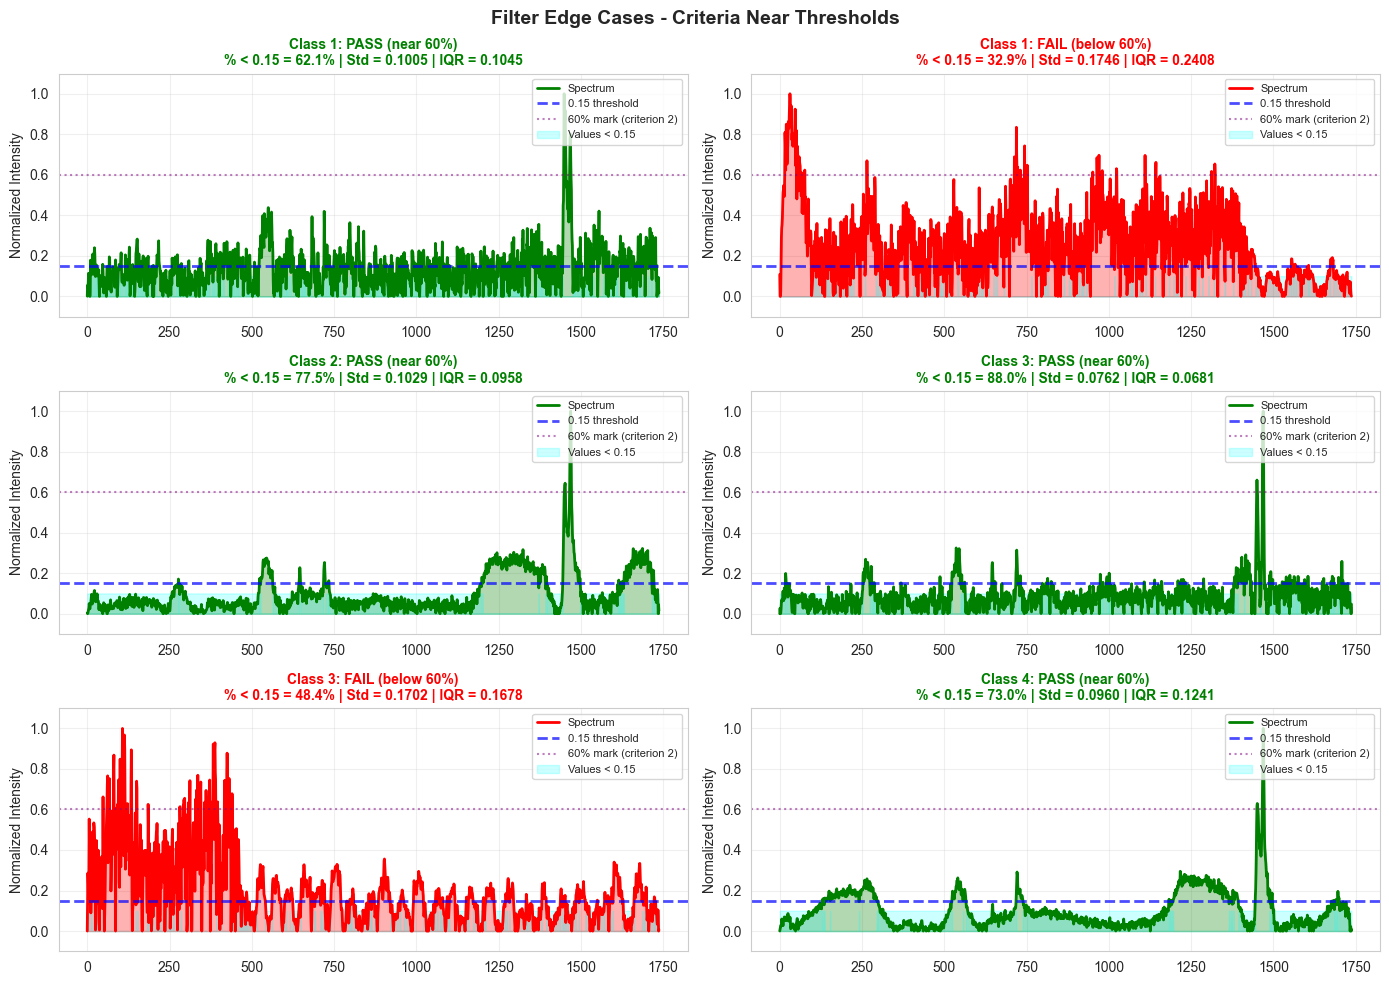

✓ Edge cases detailed analysis saved!


In [15]:
print("\n" + "="*80)
print("EDGE CASES DETAILED ANALYSIS")
print("="*80 + "\n")

# Show specific edge cases where filter decisions are most critical
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
fig.suptitle('Filter Edge Cases - Criteria Near Thresholds', fontsize=14, fontweight='bold')

edge_cases_to_show = []

# For each class, find the most interesting edge cases
for class_name, data in sorted(edge_cases_by_class.items()):
    class_num = int(class_name.split()[-1])
    
    if len(data['passed']) == 0 or len(data['failed']) == 0:
        continue
    
    # Find passed spectrum closest to 60% threshold for criterion 2
    passed_specs_near_60 = []
    for idx, spec in enumerate(data['passed']):
        metrics = compute_quality_metrics(spec, preprocessor_test)
        dist_to_60 = abs(metrics['pct_low'] - 60)
        passed_specs_near_60.append((dist_to_60, idx, spec, metrics, 'pct_low'))
    
    if passed_specs_near_60:
        edge_case = min(passed_specs_near_60)
        edge_cases_to_show.append((class_num, edge_case[1], edge_case[2], edge_case[3], 'PASS (near 60%)'))
    
    # Find failed spectrum closest to 60% threshold
    failed_specs_near_60 = []
    for idx, spec in enumerate(data['failed']):
        metrics = compute_quality_metrics(spec, preprocessor_test)
        dist_to_60 = abs(metrics['pct_low'] - 60)
        failed_specs_near_60.append((dist_to_60, idx, spec, metrics, 'pct_low'))
    
    if failed_specs_near_60:
        edge_case = min(failed_specs_near_60)
        if edge_case[3]['pct_low'] < 60:  # Show one that failed this check
            edge_cases_to_show.append((class_num, edge_case[1], edge_case[2], edge_case[3], 'FAIL (below 60%)'))

# Take the first 6 edge cases
for plot_idx, (class_num, spec_idx, spec, metrics, label) in enumerate(edge_cases_to_show[:6]):
    row, col = divmod(plot_idx, 2)
    ax = axes[row, col]
    
    # Determine color based on pass/fail
    color = 'green' if 'PASS' in label else 'red'
    
    ax.plot(spec, color=color, linewidth=2, label='Spectrum')
    ax.fill_between(range(len(spec)), spec, alpha=0.3, color=color)
    ax.axhline(0.15, color='blue', linestyle='--', linewidth=2, alpha=0.7, label='0.15 threshold')
    ax.axhline(0.60, color='purple', linestyle=':', linewidth=1.5, alpha=0.5, label='60% mark (criterion 2)')
    
    # Highlight region < 0.15
    below_015 = spec < 0.15
    ax.fill_between(range(len(spec)), 0, below_015*0.1, alpha=0.2, color='cyan', label='Values < 0.15')
    
    ax.set_title(f'Class {class_num}: {label}\n'
                f'% < 0.15 = {metrics["pct_low"]:.1f}% | Std = {metrics["std"]:.4f} | IQR = {metrics["iqr"]:.4f}',
                fontsize=10, fontweight='bold', color=color)
    ax.set_ylabel('Normalized Intensity')
    ax.set_ylim([-0.1, 1.1])
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=8)

# Hide unused subplots
for idx in range(len(edge_cases_to_show), 6):
    row, col = divmod(idx, 2)
    axes[row, col].axis('off')

plt.tight_layout()
plt.savefig("../results/data_quality/quality_filter_edge_cases.png", dpi=150, bbox_inches='tight')
plt.show()

print(" Edge cases detailed analysis saved!")


In [ ]:
print("\n" + "="*80)
print("QUALITY CRITERIA PASS/FAIL MATRIX")
print("="*80 + "\n")

# Create a detailed table showing criterion by criterion for selected spectra
print("Showing why specific spectra PASS or FAIL:\n")

for class_name, data in sorted(edge_cases_by_class.items()):
    class_num = int(class_name.split()[-1])
    
    # Thresholds
    THRESH_MIN_SIGNAL = 0.05
    THRESH_PCT_LOW = 60.0
    THRESH_STD = 0.02
    THRESH_IQR = 0.03
    THRESH_LIPID = 0.80
    THRESH_LIPID_MIN = 0.30
    
    print(f"\n{class_name} - PASSING SPECTRUM (n={len(data['passed'])} pass)")
    print("-" * 100)
    
    if len(data['passed']) > 0:
        spec = data['passed'][0]
        metrics = compute_quality_metrics(spec, preprocessor_test)
        
        print(f"  Criterion 1: Max intensity {metrics['max']:.4f} > {THRESH_MIN_SIGNAL:.4f}? {' PASS' if metrics['max'] > THRESH_MIN_SIGNAL else ' FAIL'}")
        print(f"  Criterion 2: % < 0.15 = {metrics['pct_low']:.1f}% >= {THRESH_PCT_LOW:.0f}%? {' PASS' if metrics['pct_low'] >= THRESH_PCT_LOW else ' FAIL'}")
        print(f"  Criterion 3: Lipid max {metrics['lipid_max']:.4f} >= interior {metrics['interior_max']:.4f} * 0.8 = {metrics['interior_max']*0.8:.4f}? ", end="")
        print(f"{' PASS' if metrics['lipid_max'] >= metrics['interior_max']*0.8 else ' FAIL'}", end="")
        print(f" AND Lipid {metrics['lipid_max']:.4f} >= {THRESH_LIPID_MIN:.2f}? {' PASS' if metrics['lipid_max'] >= THRESH_LIPID_MIN else ' FAIL'}")
        print(f"  Criterion 4: Std {metrics['std']:.4f} > {THRESH_STD:.4f}? {' PASS' if metrics['std'] > THRESH_STD else ' FAIL'}")
        print(f"  Criterion 5: IQR {metrics['iqr']:.4f} > {THRESH_IQR:.4f}? {' PASS' if metrics['iqr'] > THRESH_IQR else ' FAIL'}")
        print(f"  → Overall:  PASS (passes all 5 criteria)")
    
    print(f"\n{class_name} - FAILING SPECTRUM (n={len(data['failed'])} fail)")
    print("-" * 100)
    
    if len(data['failed']) > 0:
        # Find the failed spectrum that fails fewest criteria (to show edge case)
        best_failed = None
        min_failures = 6
        
        for spec in data['failed']:
            metrics = compute_quality_metrics(spec, preprocessor_test)
            failures = 0
            if metrics['max'] <= THRESH_MIN_SIGNAL:
                failures += 1
            if metrics['pct_low'] < THRESH_PCT_LOW:
                failures += 1
            if metrics['lipid_max'] < metrics['interior_max']*0.8 or metrics['lipid_max'] < THRESH_LIPID_MIN:
                failures += 1
            if metrics['std'] <= THRESH_STD:
                failures += 1
            if metrics['iqr'] <= THRESH_IQR:
                failures += 1
            
            if failures < min_failures:
                min_failures = failures
                best_failed = (spec, metrics)
        
        if best_failed:
            spec, metrics = best_failed
            
            failures = []
            
            check1 = metrics['max'] > THRESH_MIN_SIGNAL
            print(f"  Criterion 1: Max intensity {metrics['max']:.4f} > {THRESH_MIN_SIGNAL:.4f}? {' PASS' if check1 else ' FAIL'}")
            if not check1:
                failures.append("Signal too low")
            
            check2 = metrics['pct_low'] >= THRESH_PCT_LOW
            print(f"  Criterion 2: % < 0.15 = {metrics['pct_low']:.1f}% >= {THRESH_PCT_LOW:.0f}%? {' PASS' if check2 else ' FAIL'}")
            if not check2:
                failures.append(f"Only {metrics['pct_low']:.1f}% < 0.15 (need ≥60%)")
            
            check3a = metrics['lipid_max'] >= metrics['interior_max']*0.8
            check3b = metrics['lipid_max'] >= THRESH_LIPID_MIN
            check3 = check3a and check3b
            print(f"  Criterion 3: Lipid max {metrics['lipid_max']:.4f} >= interior {metrics['interior_max']:.4f} * 0.8 = {metrics['interior_max']*0.8:.4f}? {' PASS' if check3a else ' FAIL'}", end="")
            print(f" AND Lipid {metrics['lipid_max']:.4f} >= {THRESH_LIPID_MIN:.2f}? {' PASS' if check3b else ' FAIL'}")
            if not check3:
                failures.append("Lipid peak not dominant")
            
            check4 = metrics['std'] > THRESH_STD
            print(f"  Criterion 4: Std {metrics['std']:.4f} > {THRESH_STD:.4f}? {' PASS' if check4 else ' FAIL'}")
            if not check4:
                failures.append(f"Spectrum too flat (std={metrics['std']:.4f})")
            
            check5 = metrics['iqr'] > THRESH_IQR
            print(f"  Criterion 5: IQR {metrics['iqr']:.4f} > {THRESH_IQR:.4f}? {' PASS' if check5 else ' FAIL'}")
            if not check5:
                failures.append("Peak structure too weak")
            
            print(f"  → Overall:  FAIL (fails {len(failures)} criterion/criteria: {', '.join(failures)})")

print("\n" + "="*80)


SUMMARY: What Each Criterion Filters Out



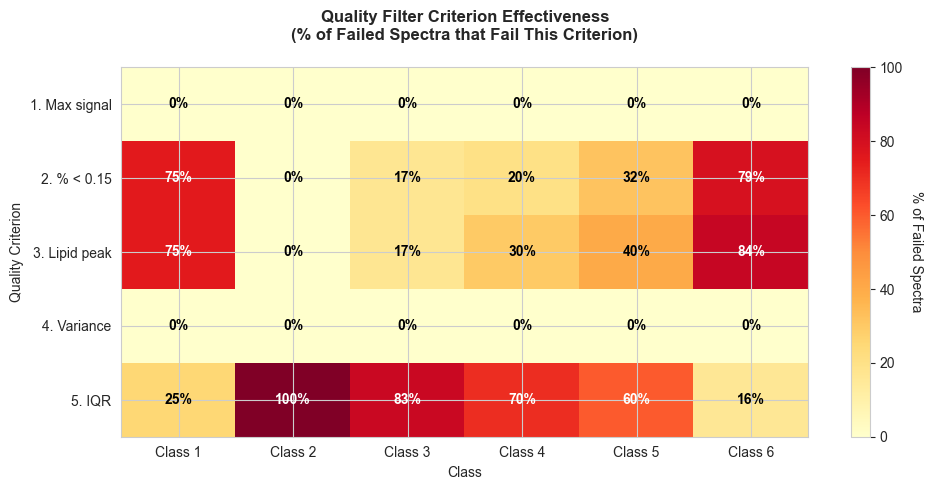


✓ Criterion effectiveness heatmap saved!

CRITERION EFFECTIVENESS BY CLASS

Percentage of failed spectra that fail each criterion:

Criterion           Class 1    Class 2    Class 3    Class 4    Class 5    Class 6    
--------------------------------------------------------------------------------
1. Max signal            0%         0%         0%         0%         0%         0%    
2. % < 0.15             75%         0%        17%        20%        32%        79%    
3. Lipid peak           75%         0%        17%        30%        40%        84%    
4. Variance              0%         0%         0%         0%         0%         0%    
5. IQR                  25%       100%        83%        70%        60%        16%    



In [14]:
print("SUMMARY: What Each Criterion Filters Out\n")

# For each criterion, calculate how many failed spectra fail that specific criterion
criterion_effectiveness = {
    '1. Max signal': [],
    '2. % < 0.15': [],
    '3. Lipid peak': [],
    '4. Variance': [],
    '5. IQR':[],
}

for class_name, data in sorted(edge_cases_by_class.items()):
    class_num = int(class_name.split()[-1])
    
    THRESH_MIN_SIGNAL = 0.05
    THRESH_PCT_LOW = 60.0
    THRESH_STD = 0.02
    THRESH_IQR = 0.03
    THRESH_LIPID = 0.80
    THRESH_LIPID_MIN = 0.30
    
    c1_fail = 0
    c2_fail = 0
    c3_fail = 0
    c4_fail = 0
    c5_fail = 0
    
    for spec in data['failed']:
        metrics = compute_quality_metrics(spec, preprocessor_test)
        
        if metrics['max'] <= THRESH_MIN_SIGNAL:
            c1_fail += 1
        if metrics['pct_low'] < THRESH_PCT_LOW:
            c2_fail += 1
        if metrics['lipid_max'] < metrics['interior_max']*0.8 or metrics['lipid_max'] < THRESH_LIPID_MIN:
            c3_fail += 1
        if metrics['std'] <= THRESH_STD:
            c4_fail += 1
        if metrics['iqr'] <= THRESH_IQR:
            c5_fail += 1
    
    total_failed = len(data['failed'])
    
    criterion_effectiveness['1. Max signal'].append(100*c1_fail/max(total_failed, 1))
    criterion_effectiveness['2. % < 0.15'].append(100*c2_fail/max(total_failed, 1))
    criterion_effectiveness['3. Lipid peak'].append(100*c3_fail/max(total_failed, 1))
    criterion_effectiveness['4. Variance'].append(100*c4_fail/max(total_failed, 1))
    criterion_effectiveness['5. IQR'].append(100*c5_fail/max(total_failed, 1))

# Create heatmap showing criterion effectiveness
fig, ax = plt.subplots(figsize=(10, 5))

data_matrix = []
criteria_names = list(criterion_effectiveness.keys())
class_names_list = sorted([f"Class {i}" for i in range(1, 7)])

for criterion in criteria_names:
    data_matrix.append(criterion_effectiveness[criterion])

data_matrix = np.array(data_matrix)

im = ax.imshow(data_matrix, cmap='YlOrRd', aspect='auto', vmin=0, vmax=100)

# Set ticks and labels
ax.set_xticks(np.arange(len(class_names_list)))
ax.set_yticks(np.arange(len(criteria_names)))
ax.set_xticklabels(class_names_list)
ax.set_yticklabels(criteria_names)

# Rotate the tick labels
plt.setp(ax.get_xticklabels(), rotation=0, ha="center", rotation_mode="anchor")

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('% of Failed Spectra', rotation=270, labelpad=15)

# Add text annotations
for i in range(len(criteria_names)):
    for j in range(len(class_names_list)):
        value = data_matrix[i, j]
        text = ax.text(j, i, f'{value:.0f}%', ha="center", va="center", 
                      color="black" if value < 50 else "white", fontweight='bold', fontsize=10)

ax.set_title('Quality Filter Criterion Effectiveness\n(% of Failed Spectra that Fail This Criterion)', 
            fontsize=12, fontweight='bold', pad=20)
ax.set_xlabel('Class')
ax.set_ylabel('Quality Criterion')

plt.tight_layout()
plt.savefig("../results/data_quality/quality_filter_criterion_effectiveness.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n Criterion effectiveness heatmap saved!")

# Print text summary
print("\n" + "="*80)
print("CRITERION EFFECTIVENESS BY CLASS")
print("="*80)
print("\nPercentage of failed spectra that fail each criterion:\n")

print(f"{'Criterion':<20}", end="")
for class_num in range(1, 7):
    print(f"Class {class_num}    ", end="")
print()

print("-" * 80)

for crit_idx, criterion_name in enumerate(criteria_names):
    print(f"{criterion_name:<20}", end="")
    for class_idx in range(6):
        value = data_matrix[crit_idx, class_idx]
        print(f"{value:>6.0f}%    ", end="")
    print()

print("\n" + "="*80)
